### 컬럼

order_id
- 주문 ID

product_id
- 상품 ID

category
- 상품 카테고리

sku_option
- 상품 옵션 정보
- 미집/토트분실 대체 재사용 판단 시 동일 SKU 매칭 기준

worker_type
- 작업자 유형
- 오집/미집에만 숙련자/비숙련자 부여

is_peak_time
- 피크 시간 여부

cancel_reason
- 취소 사유
- 단순취소 / 오집 / 미집 / 집품파손 / 리빈파손 / 토트분실

cancel_time
- 취소 발생 시점

stock_location
- 재고 위치

location_known
- 재고 위치 정보 존재 여부
- 개선 후 자동화 시 95%로 상향 가정

process_type
- 처리 방식
- manual / automated

process_time
- 취소 처리 완료 시점

process_delay_min
- 취소 발생부터 처리 완료까지 걸린 시간
- process_time - cancel_time

restock_flag
- 재고 반영 여부
- 오집은 처리 지연에 따라 확률 결정
- 미집/파손은 0
- 단순취소는 1

inspection_flag
- 검수 통과 여부
- 오집/미집/토트분실 대상
- 검수 통과율 90%

search_start_time
- 재사용 탐색 시작 시점

search_end_time
- 재사용 탐색 종료 시점

search_wait_min
- 탐색 대기 시간
- 수동은 10~60분
- 자동화는 0분

search_time_min
- 총 탐색 소요 시간
- 수동: 대기 + 탐색 + 현장 확인
- 자동화: 순수 탐색 시간

reused_flag
- 재사용 성공 여부
- 핵심 KPI: 재사용률 계산에 사용

additional_cancel_flag
- 추가취소 발생 여부
- 핵심 KPI: 추가취소율 계산에 사용

MANUAL_MATCH_MISS_PROB
- 매칭 실패 여부
- 보조 KPI : 개선 원인 설명 지표

### 분석 단계

STEP 1. 라이브러리 & 파라미터 설정
- 주문량, 취소율, 취소 사유 비율, 처리속도, 검수율, 재사용 확률 정의

STEP 2. 주문 데이터 생성
- 주문 ID, 상품, 카테고리, 옵션, 주문시간, 피크시간 생성

STEP 3. 취소 발생 & 유형/사유 부여
- 전체 주문 중 취소 샘플링
- 단순취소/운영취소 구분
- 운영취소 내 오집/미집/파손/토트분실 사유 부여

STEP 4. 처리 시간 & 재고 반영
- 수동 처리 큐 기반 process_time/process_delay_min 생성
- 단순취소는 운영 큐 제외
- 오집 재고 반영 여부 restock_flag 생성
- wrong_pick_pool 생성

STEP 5. 검수/재사용/추가취소 지표 생성
- inspection_flag 생성
- reused_flag 생성
- additional_cancel_flag 생성

STEP 6. 탐색 시간 생성 & 최종 컬럼 정렬
- search_start_time/search_end_time 생성
- search_wait_min/search_time_min 생성
- 최종 분석용 데이터 final_df 생성

STEP 7. 1단계 분석 — 전체 현황
- 전체 취소 건수, 운영취소 건수, 재사용률, 추가취소율 확인

STEP 8. 2단계 분석 — 지연 분석
- 처리 지연 구간별 재사용률 분석
- 30분 기준 지연 여부와 재사용률 관계 확인

STEP 9. 3단계 분석 — 사유 분석
- 취소 사유별 재사용률 확인
- 추가취소건 사유 비중 파이차트 확인
- 오집/미집/토트분실 상세 지표 확인

STEP 10. 4단계 분석 — 카테고리 분석
- 카테고리별 운영취소 건수
- 카테고리별 재사용률
- 카테고리별 추가취소율 확인

STEP 11. 5단계 분석 — 운영 개선 시뮬레이션
- 자동화 처리속도 적용
- 위치정보 확인률 상향
- 개선 후 restock/reuse/additional_cancel/search_time 재계산
- 수동 vs 자동화 핵심 지표 비교

STEP 12. 월별/연간 개선 효과 추정
- 일 주문량, 주문량 증가, 월별 오차를 반영
- 연간 추가취소 감소 건수
- 연간 재사용 증가 건수 추정

STEP 13. 저장
- simulation_data.csv
- simulation_improved.csv 저장

In [ ]:
# 한글 폰트 설치 (최초 1회만 실행)
!apt-get install -y fonts-nanum
import matplotlib.font_manager as fm
fm._load_fontmanager(try_read_cache=False)

import matplotlib
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 24 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (19.7 MB/s)
Selecting previously unselected package fonts-nanum.
(Reading database ... 118332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


## **STEP1 - 라이브러리 & 파라미터**

In [ ]:
# =============================================
# STEP 1: 라이브러리 & 파라미터
# =============================================
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'NanumGothic'

# 랜덤 시드 고정
np.random.seed(42)
random.seed(42)

# ── 시뮬레이션 규모 설정 ──────────────────────────
N_ORDERS    = 150000
CANCEL_RATE = 0.05   # 전체 주문 대비 취소율 고정

# ── 취소 유형 비율 (전체 취소 기준) ──────────
CANCEL_TYPE_WEIGHTS = {
    '단순취소': 0.70,
    '운영취소': 0.30,
}

# ── 운영취소 내 사유 비율 ─────────────────────
# 전체 취소 대비: 오집 16.5% / 미집 7.5% / 집품파손 1.5% / 리빈파손 1.5% / 토트분실 3%
CANCEL_REASON_WEIGHTS = {
    '오집':     0.55,
    '미집':     0.25,
    '집품파손': 0.05,
    '리빈파손': 0.05,
    '토트분실': 0.10,
}

# ── 작업자 구성 ───────────────────────────────
# 오집/미집인 경우에만 작업자 유형 부여
WORKER_EXPERIENCED_RATIO = 0.67
WORKER_NOVICE_RATIO      = 1 - WORKER_EXPERIENCED_RATIO

# ── 카테고리 ─────────────────────────────────                       ** 이부분 제외 **
CATEGORIES       = ['채소', '과일', '가공식품', '우유', '축산']
CATEGORY_WEIGHTS = [0.20, 0.20, 0.30, 0.15, 0.15]
# TODO: 실제 카테고리별 취급 비중으로 교체

# ── 카테고리별 재사용 확률 (오집 기준) ────────                                                ** 이부분도 빼도 될듯? 카테고리별 취소율은 그닥 의미가 없음(근데 그냥 한번 봤다고 치고 넣어놓을까 싶기도 하고)**
REUSE_PROB = {
    '채소':     0.30,
    '과일':     0.35,
    '가공식품': 0.80,
    '우유':     0.55,
    '축산':     0.50,
}

# ── 처리 지연 임계값 ─────────────────────────
DELAY_THRESHOLD_MIN = 30

# ── 시뮬레이션 기간 ──────────────────────────          시뮬용 24시간 데이터 생성
START_DATE = datetime(2024, 1, 1, 8, 0, 0)
SIM_DAYS   = 1

# ============================================================
# [수정] 처리 방식별 처리 속도 파라미터
# - 기존(수동)  : 작업자가 직접 취소 처리 → 60분당 약 200건
# - 자동화      : 프로그램이 취소 처리    → 60분당 약 420건
# ============================================================
MANUAL_THROUGHPUT    = 200   # 수동 처리: 60분당 처리 건수
AUTOMATED_THROUGHPUT = 420   # 자동화 처리: 60분당 처리 건수

# 건당 처리 소요 시간 (분)
MANUAL_TIME_PER_CASE    = round(60 / MANUAL_THROUGHPUT, 2)     # = 0.3분/건
AUTOMATED_TIME_PER_CASE = round(60 / AUTOMATED_THROUGHPUT, 2)  # ≒ 0.14분/건

# ============================================================
# 기존(수동) 처리 시 탐색 현장 검증 추가 딜레이
# - 검수(inspection, 90%)는 수동/자동화 공통으로 적용
# - 수동은 검수와 별개로, 탐색 시 작업자가 현장에서
#   상품 위치·상태를 직접 확인하는 시간이 추가로 발생
# - 이 현장 확인 시간을 search_time_min 에 추가 가중
# ============================================================
MANUAL_ONSITE_VERIFY_RANGE = (0.5, 2.0)                                                # 현장 검증 추가 소요 시간 범위 (분)

# ============================================================
# [수정] 탐색 대기 시간 파라미터
# - 수동: 담당자가 바빠서 탐색을 후순위로 미룸 → 10~60분 대기
# - 자동화: 검색으로 즉시 탐색 가능 → 대기 없음(0분)
# ============================================================
MANUAL_SEARCH_WAIT_RANGE = (10, 60)  # 수동 탐색 대기 시간 범위 (분)
AUTOMATED_SEARCH_WAIT    = 0         # 자동화: 즉시 탐색 (대기 없음)

# 수동 탐색 시 일치 상품을 놓칠 확률
MANUAL_MATCH_MISS_PROB = 0.10


## **STEP2 - 주문 데이터 생성**

In [ ]:
# =============================================
# STEP 2: 전체 주문 데이터 생성
# =============================================

# 셀 단위 시드 고정
random.seed(42)
np.random.seed(42)

def generate_orders(n):
    order_times = []
    for _ in range(n):
        day    = random.randint(0, SIM_DAYS - 1)
        hour   = random.choices(range(8, 23),
                                weights=[3,4,6,8,8,7,6,7,8,9,8,7,6,5,4], k=1)[0]
        minute = random.randint(0, 59)
        order_times.append(START_DATE + timedelta(days=day, hours=hour-8, minutes=minute))
    # TODO: 실제 주문 시간 분포로 교체

    # 피크 타임: 11~13시 / 17~19시                                                          # 운영시 샘플 데이터 생성을 위한 피크타임 설정 실제 운영 마감시간으로 변경(11~12, 20~24)
    # TODO: 실제 운영 피크 시간대 정의로 교체
    is_peak = [1 if t.hour in [11,12,20,21,22,23,24] else 0 for t in order_times]

    return pd.DataFrame({
        'order_id':     [f'ORD-{str(i).zfill(6)}' for i in range(1, n+1)],
        'product_id':   [f'PRD-{str(random.randint(1,500)).zfill(4)}' for _ in range(n)],
        'category':     random.choices(CATEGORIES, weights=CATEGORY_WEIGHTS, k=n),
        'sku_option':   [f'OPT-{random.randint(1,3):02d}' for _ in range(n)],
        'order_time':   order_times,
        'is_peak_time': is_peak,
    })

orders_df = generate_orders(N_ORDERS)
print(f"전체 주문 수: {len(orders_df):,}")

전체 주문 수: 150,000


## **STEP3 - 취소 발생&유형/사유 부여**

In [ ]:
# =============================================
# STEP 3: 취소 발생 & cancel_reason 부여
# =============================================

# 셀 단위 시드 고정
random.seed(43)
np.random.seed(43)

def assign_cancel_reason(row):

    # STEP 1에서 정의한 취소 유형 비율을 기준으로 단순취소 / 운영취소를 먼저 결정한다.                  *** 단순취소는 뭔가 싶긴 한데.. 고객취소로 바꿔야 되나 ㅇㅅㅇ..
    # 운영취소일 경우 세부 사유를 부여하고,그중 오집/미집에만 작업자 유형을 부여한다.

    # 1) STEP 1의 취소 유형 비율 기준으로 단순취소 / 운영취소 결정
    cancel_type = random.choices(
        list(CANCEL_TYPE_WEIGHTS.keys()),
        weights=list(CANCEL_TYPE_WEIGHTS.values()),
        k=1
    )[0]

    # 2) 단순취소면 작업자 유형 없음
    if cancel_type == '단순취소':
        reason = '단순취소'
        w_type = '해당없음'

    # 3) 운영취소면 세부 사유 결정
    else:
        reason = random.choices(
            list(CANCEL_REASON_WEIGHTS.keys()),
            weights=list(CANCEL_REASON_WEIGHTS.values()),
            k=1
        )[0]

        # 4) 오집/미집에만 작업자 유형 부여
        if reason in ['오집', '미집']:
            is_exp = random.random() < WORKER_EXPERIENCED_RATIO
            w_type = '숙련자' if is_exp else '비숙련자'
        else:
            w_type = '해당없음'

    return w_type, reason


# 취소 샘플링
n_cancel  = int(N_ORDERS * CANCEL_RATE)
cancel_df = orders_df.sample(n=n_cancel, random_state=42).copy().reset_index(drop=True)

# 취소 발생 시점 (주문 후 1~30분)                                                      **출고 완료 까지 대략 30분 이내로 가정
cancel_df['cancel_time'] = cancel_df['order_time'].apply(
    lambda t: t + timedelta(minutes=random.randint(1, 30))
)

# 취소 사유 부여
result = cancel_df.apply(assign_cancel_reason, axis=1)
cancel_df['worker_type']   = [r[0] for r in result]
cancel_df['cancel_reason'] = [r[1] for r in result]

# 재고 위치 & 위치 정보 여부
# TODO: 실제 창고 구역 코드로 교체
cancel_df['stock_location'] = [
    f'{random.choice(["A","B","C","D","E"])}-{random.randint(1,20):02d}'
    for _ in range(len(cancel_df))
]
cancel_df['location_known'] = [
    1 if random.random() < 0.60 else 0
    for _ in range(len(cancel_df))
]

print("[ cancel_reason 분포 ]")
print(cancel_df['cancel_reason'].value_counts(normalize=True).round(3))

[ cancel_reason 분포 ]
cancel_reason
단순취소    0.699
오집      0.170
미집      0.073
토트분실    0.030
리빈파손    0.016
집품파손    0.012
Name: proportion, dtype: float64


## **STEP4 - 처리 시간 & 재고 반영**

In [ ]:
# =============================================
# STEP 4: 처리 시간 & restock_flag & 오집 재고 풀
# =============================================

# ============================================================
# STEP 4 수정: 수동 처리 기준 process_time / process_delay_min 생성
# - 같은 발생 분(minute)에 몰린 취소건을 순차 처리
# - 수동: 건당 0.3분
# - 30~50건 처리 후 2~5분 정리 딜레이 부여
# ============================================================

# [수정] 셀 단위 시드 고정 — 셀 재실행 순서와 무관하게 동일 결과 보장
random.seed(44)
np.random.seed(44)

def assign_process_time_by_queue(
    df,
    time_per_case,
    process_type='manual',
    batch_range=(30, 50),
    break_range=(2, 3)
):
    result = df.copy()
    result = result.sort_values('cancel_time').reset_index(drop=True)

    process_times = []
    last_process_time = None
    batch_count = 0
    next_batch_limit = random.randint(*batch_range)

    for _, row in result.iterrows():
        cancel_time = row['cancel_time']

        # 첫 건이거나 이전 처리 완료 시간이 현재 취소 발생보다 빠르면,
        # 현재 취소 발생 시점부터 처리 시작
        if last_process_time is None or last_process_time < cancel_time:
            last_process_time = cancel_time

        # 건당 처리 시간 추가
        last_process_time = last_process_time + timedelta(minutes=time_per_case)
        batch_count += 1

        process_times.append(last_process_time)

        # 수동 처리만 일정 건수 처리 후 정리 딜레이 부여
        if process_type == 'manual' and batch_count >= next_batch_limit:
            break_min = random.uniform(*break_range)
            last_process_time = last_process_time + timedelta(minutes=break_min)

            batch_count = 0
            next_batch_limit = random.randint(*batch_range)

    result['process_type'] = process_type
    result['process_time'] = process_times
    result['process_delay_min'] = (
        (result['process_time'] - result['cancel_time'])
        .dt.total_seconds() / 60
    ).round(2)

    return result


# 단순취소 / 운영취소 분리
simple_df = cancel_df[cancel_df['cancel_reason'] == '단순취소'].copy()
op_cancel_df = cancel_df[cancel_df['cancel_reason'] != '단순취소'].copy()

# 단순취소는 운영 수동 처리 큐 대상이 아니므로 즉시 처리로 가정
simple_df['process_type'] = 'manual'
simple_df['process_time'] = simple_df['cancel_time']
simple_df['process_delay_min'] = 0

# 운영취소만 수동 처리 큐 적용
op_cancel_df = assign_process_time_by_queue(
    op_cancel_df,
    time_per_case=MANUAL_TIME_PER_CASE,
    process_type='manual',
    batch_range=(30, 50),
    break_range=(2, 5)
)

# 다시 합치기
cancel_df = pd.concat([simple_df, op_cancel_df], ignore_index=True)
cancel_df = cancel_df.sort_values('cancel_time').reset_index(drop=True)

# ============================================================
# [수정] process_type 컬럼 추가
# - 기존 데이터(final_df)는 수동(manual) 처리 방식
# - 자동화(automated)는 STEP 11 개선 시뮬레이션에서 사용
# ============================================================
cancel_df['process_type'] = 'manual'

# [수정] 처리 속도 지표 출력
print("[ 처리 방식별 속도 지표 ]")
print(f"  수동 처리   : 60분당 {MANUAL_THROUGHPUT}건  (건당 {MANUAL_TIME_PER_CASE}분)")
print(f"  자동화 처리 : 60분당 {AUTOMATED_THROUGHPUT}건  (건당 {AUTOMATED_TIME_PER_CASE}분)")
print(f"  처리 속도 향상 : {AUTOMATED_THROUGHPUT / MANUAL_THROUGHPUT:.1f}배")

def decide_restock(row):
    if row['cancel_reason'] == '단순취소':
        return 1   # 단순취소 → 재고 즉시 반영
    if row['cancel_reason'] == '미집':
        return 0   # 미집 → 상품 자체 없음 (오집 재고 풀에서 대체 탐색)
    if row['cancel_reason'] in ['집품파손', '리빈파손']:
        return 0   # 파손 → 재고 반영 불가
    # 오집: 처리 지연 길수록 반영 누락 확률 증가
    # TODO: 실제 누락률 데이터로 보정
    miss_prob = 0.05 + (row['process_delay_min'] / 100) * 0.10
    miss_prob = min(miss_prob, 0.10)
    return 0 if random.random() < miss_prob else 1

cancel_df['restock_flag'] = cancel_df.apply(decide_restock, axis=1)

# ── 오집 재고 풀 생성 (미집 대체 재사용용) ────
# 오집 중 재고 반영된 건을 SKU별로 모아둠
wrong_pick_pool = (
    cancel_df[
        (cancel_df['cancel_reason'] == '오집') &
        (cancel_df['restock_flag'] == 1)
    ]
    .groupby(['product_id', 'sku_option'])
    .size()
    .reset_index(name='available_count')
)

print("\n[ restock_flag ]")
print(cancel_df['restock_flag'].value_counts())
print(f"\n오집 재고 풀 SKU 수: {len(wrong_pick_pool):,}")


[ 처리 방식별 속도 지표 ]
  수동 처리   : 60분당 200건  (건당 0.3분)
  자동화 처리 : 60분당 420건  (건당 0.14분)
  처리 속도 향상 : 2.1배

[ restock_flag ]
restock_flag
1    6610
0     890
Name: count, dtype: int64

오집 재고 풀 SKU 수: 797


## **STEP5 - 검수/재사용/추가 취소**

In [ ]:
# =============================================
# STEP 5: inspection_flag / reused_flag / additional_cancel_flag
# =============================================

# ── inspection_flag ──────────────────────────
# ============================================================
# [수정] decide_inspection
# - 검수는 수동/자동화 공통 적용: 재사용에 부적합한 상품은
#   처리 방식과 무관하게 걸러지므로 통과율 90%를 동일하게 적용
# - (수동은 이와 별개로 탐색 시 현장 확인 시간이 search_time에 가중됨)
# ============================================================
# [수정] 셀 단위 시드 고정 — 셀 재실행 순서와 무관하게 동일 결과 보장
random.seed(45)
np.random.seed(45)

def decide_inspection(row):
    if row['cancel_reason'] not in ['오집','미집','토트분실']:
        return 0

    if row['cancel_reason'] == '오집' and row['restock_flag'] == 0:
        return 0

    return 1 if random.random() < 0.90 else 0

cancel_df['inspection_flag'] = cancel_df.apply(decide_inspection, axis=1)


# ── reused_flag ──────────────────────────────
# ============================================================
# [수정] decide_reuse
# 버그 수정: 기존 코드는 inspection_flag 체크 안에서
#   restock_flag=0 → inspection=0 → reuse=0 이 암묵적으로 연결됐음.
#   수동에서 inspection 체크를 통째로 스킵하면서
#   restock_flag=0 게이트까지 함께 날아가는 버그 발생.
# → restock_flag 게이트를 수동/자동화 공통으로 앞에 명시하여 복원.
# → inspection_flag 체크는 자동화에서만 추가로 수행.
# ============================================================
def decide_reuse(row):
    # 단순취소 / 파손 → 재사용 대상 아님
    # [수정] 단순취소가 어떤 분기에도 걸리지 않아 None(NaN)이
    #        반환되던 버그 수정 — 명시적으로 0 반환
    if row['cancel_reason'] in ['단순취소', '집품파손', '리빈파손']:
        return 0

    if row['cancel_reason'] == '오집':
        if row['restock_flag'] == 0:
            return 0

        if row['inspection_flag'] == 0:
            return 0

        base = REUSE_PROB.get(row['category'], 0.50)

        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.70

        return 1 if random.random() < base else 0

    # 미집: 오집 재고 풀에서 동일 SKU 탐색 후 대체 재사용
    # 토트분실: 발견 지연/위치 불확실성 때문에 재사용률 낮게 설정
    if row['cancel_reason'] in ['미집', '토트분실']:
        if row['inspection_flag'] == 0:
            return 0

        matched = wrong_pick_pool[
            (wrong_pick_pool['product_id'] == row['product_id']) &
            (wrong_pick_pool['sku_option'] == row['sku_option'])
        ]

        if len(matched) == 0:
            return 0
        if random.random() < MANUAL_MATCH_MISS_PROB:
            return 0

        if row['cancel_reason'] == '미집':
            base = 0.70
        else:  # 토트분실
            base = 0.30

        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.70

        return 1 if random.random() < base else 0

    # [수정] 방어적 기본 반환값 (reuse_improved와 구조 통일)
    return 0

cancel_df['reused_flag'] = cancel_df.apply(decide_reuse, axis=1)


# ── additional_cancel_flag ───────────────────
def decide_add_cancel(row):
    """
    재사용 불가 또는 재사용 실패 건을 추가 취소로 간주한다.
    """

    if row['cancel_reason'] == '단순취소':
        return 0

    # 파손류는 재사용 불가이므로 추가취소로 간주
    if row['cancel_reason'] in ['집품파손', '리빈파손']:
        return 1

    # 재사용 가능 사유는 재사용 실패 시 추가취소
    if row['cancel_reason'] in ['오집', '미집', '토트분실']:
        return 1 if row['reused_flag'] == 0 else 0

    return 0

cancel_df['additional_cancel_flag'] = cancel_df.apply(decide_add_cancel, axis=1)

print("[ reused_flag ]")
print(cancel_df['reused_flag'].value_counts())
print("\n[ additional_cancel_flag ]")
print(cancel_df['additional_cancel_flag'].value_counts())


[ reused_flag ]
reused_flag
0    6860
1     640
Name: count, dtype: int64

[ additional_cancel_flag ]
additional_cancel_flag
0    5886
1    1614
Name: count, dtype: int64


## **STEP6 - 탐색 시간&최종 정리**

In [ ]:
# =============================================
# STEP 6: 탐색 시간 & 최종 컬럼 정렬
# =============================================

# ============================================================
# [수정] calc_search — 수동/자동화 처리 방식에 따라 탐색 시간 구조 분리
#
# 수동 처리:
#   ① 탐색 대기(search_wait_min): 담당자가 바빠서 후순위로 미룸 (10~60분)
#   ② 순수 탐색 시간: 위치 정보 유무에 따라 0~1분 or 1~3분
#   ③ 현장 검증 딜레이: 별도 inspection 없이 탐색 시 직접 확인 (0.5~2.0분)
#   → search_time_min = ① + ② + ③
#
# 자동화 처리:
#   ① 탐색 대기(search_wait_min): 즉시 탐색 가능 → 0분
#   ② 순수 탐색 시간: 위치 정보 유무에 따라 0~1분 or 1~3분
#   ③ 현장 검증: 시스템 검색으로 현장 확인이 불필요 → 탐색 시간에 미포함
#      (검수 inspection은 수동/자동화 공통의 별도 단계)
#   → search_time_min = ② 만
# ============================================================
# [수정] 셀 단위 시드 고정 — 셀 재실행 순서와 무관하게 동일 결과 보장
random.seed(46)
np.random.seed(46)

def calc_search(row):
    # 오집 + 재고 반영된 경우 / 미집·토트분실 + 재사용 성공한 경우만 탐색 시간 기록
    if row['cancel_reason'] == '오집' and row['restock_flag'] == 1:
        pass
    elif row['cancel_reason'] in ['미집', '토트분실'] and row['reused_flag'] == 1:
        pass
    else:
        return None, None, None, None

    start = row['process_time']

    # 위치 정보에 따른 순수 탐색 시간
    # TODO: 개선 후 시나리오에서 location_known 비율 높여 비교
    t_search = round(random.uniform(0, 1), 1) if row['location_known'] \
               else round(random.uniform(1, 3), 1)

    if row.get('process_type', 'manual') == 'manual':
        # [수정] 수동: 탐색 대기 + 순수 탐색 + 현장 검증 딜레이를 합산
        wait    = round(random.uniform(*MANUAL_SEARCH_WAIT_RANGE), 1)   # 후순위 대기
        verify  = round(random.uniform(*MANUAL_ONSITE_VERIFY_RANGE), 1) # 현장 검증
        t_total = round(t_search + wait + verify, 1)
    else:
        # [수정] 자동화: 즉시 탐색 가능, 현장 검증 없음 → 순수 탐색 시간만
        wait    = AUTOMATED_SEARCH_WAIT   # = 0
        t_total = t_search

    return start, start + timedelta(minutes=t_total), t_total, wait

s = cancel_df.apply(calc_search, axis=1)
cancel_df['search_start_time'] = [r[0] for r in s]
cancel_df['search_end_time']   = [r[1] for r in s]
cancel_df['search_time_min']   = [r[2] for r in s]
cancel_df['search_wait_min']   = [r[3] for r in s]  # [수정] 탐색 대기 시간 컬럼 추가

# ── 최종 컬럼 순서 정렬 ──────────────────────
COLS = [
    'order_id', 'product_id', 'category', 'sku_option',          # 식별
    'worker_type', 'is_peak_time',                               # 작업 환경
    'cancel_reason', 'cancel_time',                              # 취소 정보
    'stock_location', 'location_known',                          # 재고 위치
    'process_type', 'process_time', 'process_delay_min',         # [수정] process_type 추가
    'restock_flag', 'inspection_flag',                           # 재고 반영 & 검수
    'search_start_time', 'search_end_time',
    'search_wait_min', 'search_time_min',                        # [수정] search_wait_min 추가
    'reused_flag', 'additional_cancel_flag',                     # 재사용 & 추가 취소
]

final_df = cancel_df[COLS].copy()

print(f"최종 데이터 shape: {final_df.shape}")
print(f"\n결측치 현황:")
print(final_df.isnull().sum()[final_df.isnull().sum() > 0])
final_df.head()


최종 데이터 shape: (7500, 21)

결측치 현황:
search_start_time    6166
search_end_time      6166
search_wait_min      6166
search_time_min      6166
dtype: int64


,order_id,product_id,category,sku_option,worker_type,is_peak_time,cancel_reason,cancel_time,stock_location,location_known,...,process_time,process_delay_min,restock_flag,inspection_flag,search_start_time,search_end_time,search_wait_min,search_time_min,reused_flag,additional_cancel_flag
0,ORD-056297,PRD-0389,축산,OPT-03,숙련자,0,미집,2024-01-01 08:01:00,A-07,1,...,2024-01-01 08:01:18,0.3,0,1,NaT,NaT,NaN,NaN,0,1
1,ORD-042434,PRD-0236,과일,OPT-03,비숙련자,0,미집,2024-01-01 08:03:00,B-01,1,...,2024-01-01 08:03:18,0.3,0,1,2024-01-01 08:03:18,2024-01-01 08:35:36,30.0,32.3,1,0
2,ORD-098324,PRD-0221,가공식품,OPT-03,비숙련자,0,오집,2024-01-01 08:05:00,A-03,1,...,2024-01-01 08:05:18,0.3,1,1,2024-01-01 08:05:18,2024-01-01 08:28:54,21.4,23.6,0,1
3,ORD-064596,PRD-0485,채소,OPT-03,해당없음,0,단순취소,2024-01-01 08:05:00,C-17,0,...,2024-01-01 08:05:00,0.0,1,0,NaT,NaT,NaN,NaN,0,0
4,ORD-017525,PRD-0202,채소,OPT-01,해당없음,0,단순취소,2024-01-01 08:06:00,A-19,1,...,2024-01-01 08:06:00,0.0,1,0,NaT,NaT,NaN,NaN,0,0


## **STEP7 - 1단계 분석**

1단계. 전체 현황

전체 취소 건수   : 7,500건
운영 취소 건수   : 2,254건
전체 재사용률    : 28.4%
추가 취소 발생률 : 71.6%

[ 취소 사유별 비중 ]
cancel_reason
단순취소    0.699
오집      0.170
미집      0.073
토트분실    0.030
리빈파손    0.016
집품파손    0.012
Name: proportion, dtype: float64


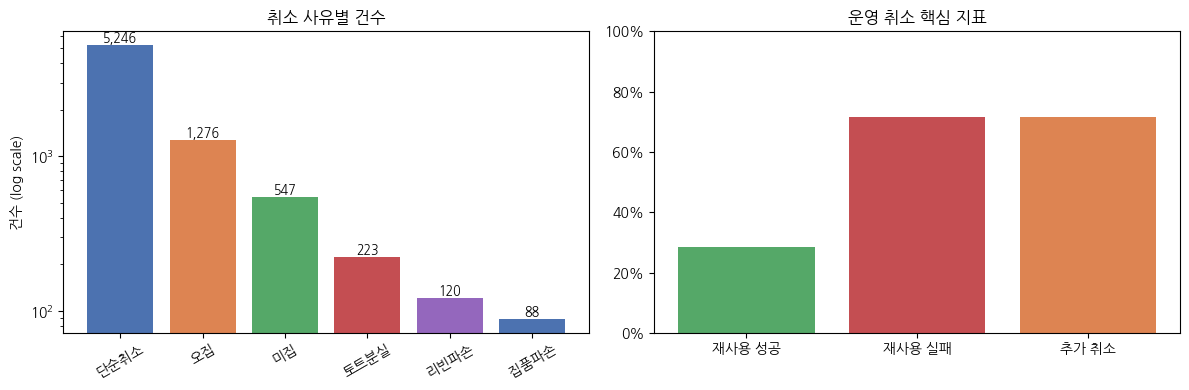

In [ ]:
# =============================================
# STEP 7: 1단계 분석 — 전체 현황
# =============================================
import matplotlib.gridspec as gridspec

op_df = final_df[final_df['cancel_reason'] != '단순취소']  # 운영취소만

print("=" * 45)
print("1단계. 전체 현황")
print("=" * 45)
print(f"\n전체 취소 건수   : {len(final_df):,}건")
print(f"운영 취소 건수   : {len(op_df):,}건")
print(f"전체 재사용률    : {op_df['reused_flag'].mean():.1%}")
print(f"추가 취소 발생률 : {op_df['additional_cancel_flag'].mean():.1%}")

print("\n[ 취소 사유별 비중 ]")
print(final_df['cancel_reason'].value_counts(normalize=True).round(3))

# =========================
# 그래프 생성
# =========================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# =========================
# 왼쪽: 취소 사유 (로그 스케일 적용)
# =========================
counts = final_df['cancel_reason'].value_counts()

bars = axes[0].bar(
    counts.index,
    counts.values,
    color=['#4C72B0','#DD8452','#55A868','#C44E52','#9467BD'][:len(counts)]
)

axes[0].set_title('취소 사유별 건수')
axes[0].set_yscale('log')  # 핵심 (엑셀 느낌)
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylabel('건수 (log scale)')

# 값 라벨 표시
for bar in bars:
    height = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom',
        fontsize=9
    )

# =========================
# 오른쪽: 운영 취소 핵심 지표
# =========================
reuse_rate    = op_df['reused_flag'].mean()
add_can_rate  = op_df['additional_cancel_flag'].mean()

axes[1].bar(
    ['재사용 성공', '재사용 실패', '추가 취소'],
    [reuse_rate, 1 - reuse_rate, add_can_rate],
    color=['#55A868','#C44E52','#DD8452']
)

axes[1].set_title('운영 취소 핵심 지표')
axes[1].set_ylim(0, 1)
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.0%}')
)

plt.tight_layout()
plt.show()

## **STEP8 - 2단계 분석**

2단계. 지연 분석

[ 지연 구간별 재사용률 ]
delay_bin
0-10      0.292
10-20     0.382
20-30     0.353
30-50     0.239
50-70     0.253
70-100    0.230
Name: reused_flag, dtype: float64

30분 이하 재사용률: 32.9%
30분 초과 재사용률: 24.1%  (차이: 8.8%p)
count    2254.000000
mean       35.658323
std        24.657813
min         0.300000
25%        16.845000
50%        30.985000
75%        58.465000
max        77.600000
Name: process_delay_min, dtype: float64
0.3
77.6
483


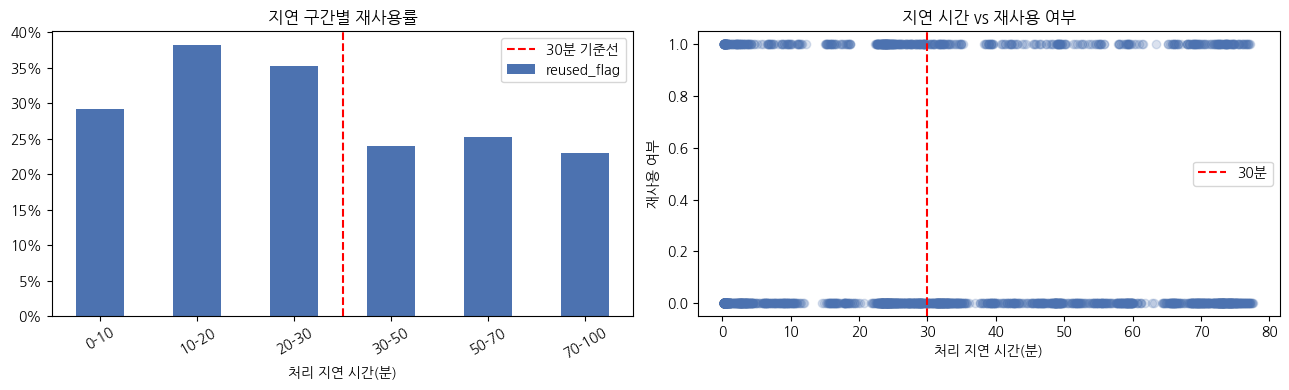

In [ ]:
# =============================================
# STEP 8: 2단계 분석 — 개선 전 지연 병 분석
# =============================================

bins   = [0, 10, 20, 30, 50, 70, 100, np.inf]
labels = ['0-10', '10-20', '20-30', '30-50', '50-70', '70-100', '100+']
op_df  = op_df.copy()
op_df['delay_bin'] = pd.cut(
    op_df['process_delay_min'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

delay_summary = op_df.groupby('delay_bin', observed=True)['reused_flag'].mean()

over  = op_df[op_df['process_delay_min'] >  DELAY_THRESHOLD_MIN]['reused_flag'].mean()
under = op_df[op_df['process_delay_min'] <= DELAY_THRESHOLD_MIN]['reused_flag'].mean()

print("=" * 45)
print("2단계. 지연 분석")
print("=" * 45)
print("\n[ 지연 구간별 재사용률 ]")
print(delay_summary.round(3))
print(f"\n30분 이하 재사용률: {under:.1%}")
print(f"30분 초과 재사용률: {over:.1%}  (차이: {under-over:.1%}p)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

delay_summary.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].axvline(x=2.5, color='red', linestyle='--', label='30분 기준선')
axes[0].set_title('지연 구간별 재사용률')
axes[0].set_xlabel('처리 지연 시간(분)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

axes[1].scatter(op_df['process_delay_min'], op_df['reused_flag'],
                alpha=0.2, color='#4C72B0')
axes[1].axvline(x=DELAY_THRESHOLD_MIN, color='red', linestyle='--', label='30분')
axes[1].set_title('지연 시간 vs 재사용 여부')
axes[1].set_xlabel('처리 지연 시간(분)')
axes[1].set_ylabel('재사용 여부')
axes[1].legend()

print(op_df['process_delay_min'].describe())
print(op_df['process_delay_min'].min())
print(op_df['process_delay_min'].max())
print(op_df['process_delay_min'].between(0, 10).sum())

plt.tight_layout()
plt.show()

## **STEP9 - 3단계 분석**

3단계. 사유 분석 (운영 취소 기준)

[ 사유별 재사용률 ]
cancel_reason
리빈파손    0.000
미집      0.260
오집      0.370
집품파손    0.000
토트분실    0.117
Name: reused_flag, dtype: float64

[ 추가 취소건 사유 비중 ]
cancel_reason
리빈파손    1.000
미집      0.740
오집      0.630
집품파손    1.000
토트분실    0.883
Name: additional_cancel_flag, dtype: float64

▶ 오집 상세
  건수             : 1,276건
  검수 통과율      : 82.8%
  재사용률         : 37.0%
  추가 취소 발생률 : 63.0%

▶ 미집 상세
  건수               : 547건
  대체 재사용률      : 26.0%
  추가 취소 발생률   : 74.0%

▶ 토트분실 상세
  건수               : 223건
  재사용률           : 11.7%
  추가 취소 발생률   : 88.3%


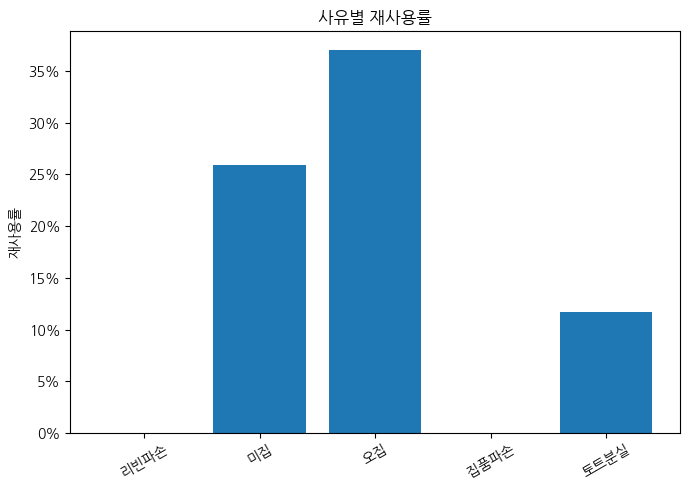

In [ ]:
# =============================================
# STEP 9: 3단계 분석 — 사유 분석
# =============================================

reason_reuse  = op_df.groupby('cancel_reason')['reused_flag'].mean()
reason_addcan = op_df.groupby('cancel_reason')['additional_cancel_flag'].mean()

print("=" * 45)
print("3단계. 사유 분석 (운영 취소 기준)")
print("=" * 45)
print("\n[ 사유별 재사용률 ]")
print(reason_reuse.round(3))
print("\n[ 추가 취소건 사유 비중 ]")
print(reason_addcan.round(3))

# 오집 상세
wp = op_df[op_df['cancel_reason'] == '오집']
print(f"\n▶ 오집 상세")
print(f"  건수             : {len(wp):,}건")
print(f"  검수 통과율      : {wp['inspection_flag'].mean():.1%}")
print(f"  재사용률         : {wp['reused_flag'].mean():.1%}")
print(f"  추가 취소 발생률 : {wp['additional_cancel_flag'].mean():.1%}")

# 미집 상세
mp = op_df[op_df['cancel_reason'] == '미집']
print(f"\n▶ 미집 상세")
print(f"  건수               : {len(mp):,}건")
print(f"  대체 재사용률      : {mp['reused_flag'].mean():.1%}")
print(f"  추가 취소 발생률   : {mp['additional_cancel_flag'].mean():.1%}")

# 토트분실 상세
tp = op_df[op_df['cancel_reason'] == '토트분실']
print(f"\n▶ 토트분실 상세")
print(f"  건수               : {len(tp):,}건")
print(f"  재사용률           : {tp['reused_flag'].mean():.1%}")
print(f"  추가 취소 발생률   : {tp['additional_cancel_flag'].mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(reason_reuse.index, reason_reuse.values)
ax.set_title('사유별 재사용률')
ax.set_xlabel('')
ax.set_ylabel('재사용률')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

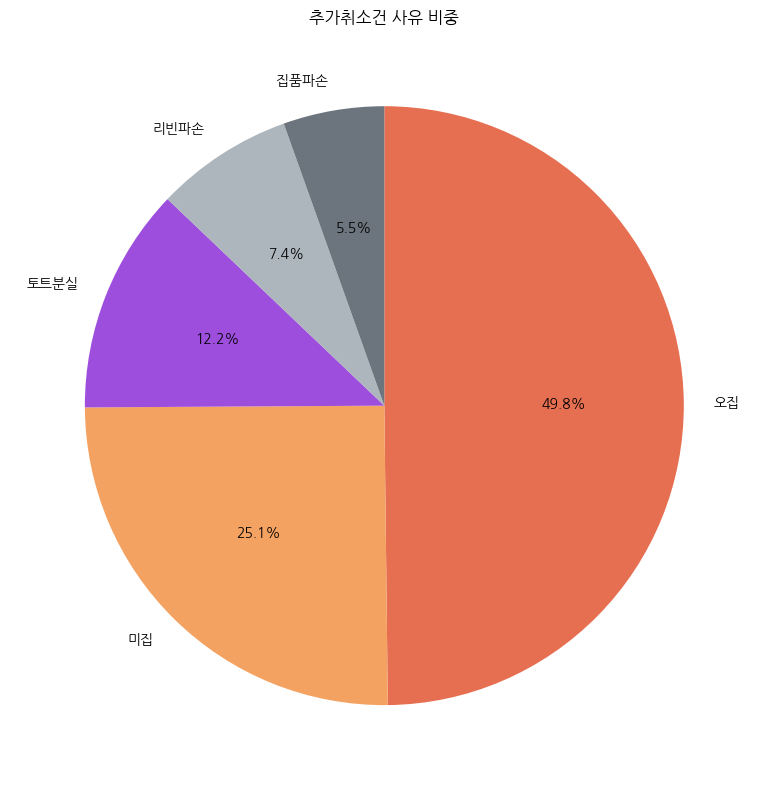

[추가취소건 사유별 건수]
cancel_reason
오집      804
미집      405
토트분실    197
리빈파손    120
집품파손     88
Name: count, dtype: int64


In [ ]:
# =============================================
# STEP 9-3: 추가취소건 사유 비중 분석
# =============================================

# 추가취소 발생 건만 추출
add_cancel_df = op_df[
    op_df['additional_cancel_flag'] == 1
].copy()

# 사유별 건수 집계 (내림차순 정렬)
reason_counts = (
    add_cancel_df['cancel_reason']
    .value_counts()
)

# 사유별 색상 지정
color_map = {
    '오집': '#e76f51',
    '미집': '#f4a261',
    '토트분실': '#9d4edd',
    '집품파손': '#6c757d',
    '리빈파손': '#adb5bd'
}

# 사유 순서에 맞춰 색상 리스트 생성
colors = [
    color_map.get(reason, '#cccccc')
    for reason in reason_counts.index
]

# 파이차트
plt.figure(figsize=(8, 8))

plt.pie(
    reason_counts,
    labels=reason_counts.index,
    autopct='%1.1f%%',
    startangle=90,       # 12시 방향 시작
    counterclock=False,  # 시계방향
    colors=colors
)

plt.title('추가취소건 사유 비중')

plt.tight_layout()
plt.show()

# 건수 출력
print("[추가취소건 사유별 건수]")
print(reason_counts.astype(int))

3단계. 사유 분석 (재사용 가능 운영취소 기준)

[ 사유별 재사용률 ]
cancel_reason
오집      0.370
미집      0.260
토트분실    0.117
Name: reused_flag, dtype: float64

[ 추가 취소 사유 비중 ]
cancel_reason
오집      0.572
미집      0.288
토트분실    0.140
dtype: float64

[ 추가 취소 건수 ]
cancel_reason
오집      804
미집      405
토트분실    197
dtype: int64

▶ 오집 상세
  건수                 : 1,276건
  검수 통과율          : 82.8%
  재사용률             : 37.0%
  추가 취소 건수       : 804건
  추가 취소 사유 비중  : 57.2%

▶ 미집 상세
  건수                 : 547건
  대체 재사용률        : 26.0%
  추가 취소 건수       : 405건
  추가 취소 사유 비중  : 28.8%

▶ 토트분실 상세
  건수                 : 223건
  재사용률             : 11.7%
  추가 취소 건수       : 197건
  추가 취소 사유 비중  : 14.0%


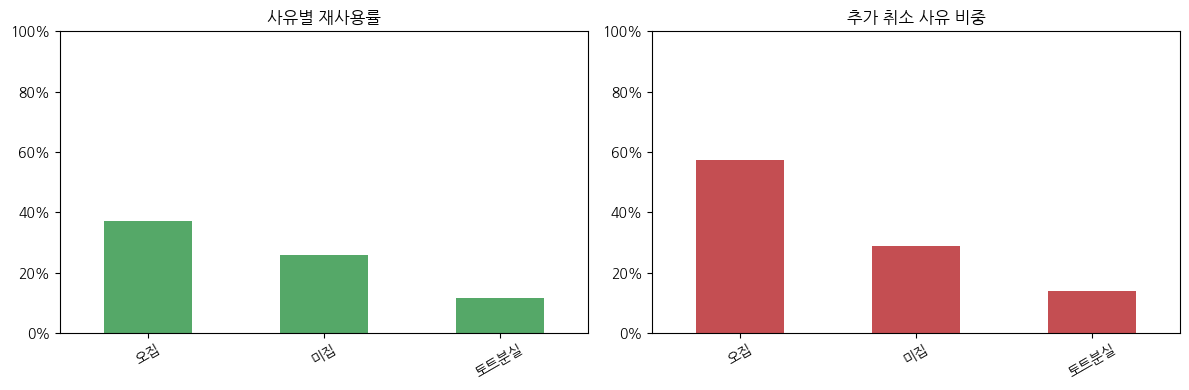

In [ ]:
# =============================================
# STEP 9: 3단계 분석 — 사유 분석
# =============================================

# 재사용 가능 사유만 분석 대상으로 설정
# 파손류는 물리적으로 재사용 불가능하므로 재사용률 비교 대상에서 제외
reusable_reasons = ['오집', '미집', '토트분실']
reason_df = op_df[op_df['cancel_reason'].isin(reusable_reasons)].copy()

# 1) 사유별 재사용률
reason_reuse = (
    reason_df
    .groupby('cancel_reason')['reused_flag']
    .mean()
    .reindex(reusable_reasons)
)

# 2) 추가 취소 사유 비중
# 의미: 추가 취소가 발생한 건 중 각 사유가 차지하는 비중
add_cancel_count = (
    reason_df[reason_df['additional_cancel_flag'] == 1]
    .groupby('cancel_reason')
    .size()
    .reindex(reusable_reasons, fill_value=0)
)

if add_cancel_count.sum() > 0:
    reason_addcan_share = add_cancel_count / add_cancel_count.sum()
else:
    reason_addcan_share = add_cancel_count * 0

print("=" * 45)
print("3단계. 사유 분석 (재사용 가능 운영취소 기준)")
print("=" * 45)

print("\n[ 사유별 재사용률 ]")
print(reason_reuse.round(3))

print("\n[ 추가 취소 사유 비중 ]")
print(reason_addcan_share.round(3))

print("\n[ 추가 취소 건수 ]")
print(add_cancel_count)

# 오집 상세
wp = reason_df[reason_df['cancel_reason'] == '오집']
wp_add_count = int(add_cancel_count.get('오집', 0))
wp_add_share = reason_addcan_share.get('오집', 0)

print(f"\n▶ 오집 상세")
print(f"  건수                 : {len(wp):,}건")
print(f"  검수 통과율          : {wp['inspection_flag'].mean():.1%}")
print(f"  재사용률             : {wp['reused_flag'].mean():.1%}")
print(f"  추가 취소 건수       : {wp_add_count:,}건")
print(f"  추가 취소 사유 비중  : {wp_add_share:.1%}")

# 미집 상세
mp = reason_df[reason_df['cancel_reason'] == '미집']
mp_add_count = int(add_cancel_count.get('미집', 0))
mp_add_share = reason_addcan_share.get('미집', 0)

print(f"\n▶ 미집 상세")
print(f"  건수                 : {len(mp):,}건")
print(f"  대체 재사용률        : {mp['reused_flag'].mean():.1%}")
print(f"  추가 취소 건수       : {mp_add_count:,}건")
print(f"  추가 취소 사유 비중  : {mp_add_share:.1%}")

# 토트분실 상세
tp = reason_df[reason_df['cancel_reason'] == '토트분실']
tp_add_count = int(add_cancel_count.get('토트분실', 0))
tp_add_share = reason_addcan_share.get('토트분실', 0)

print(f"\n▶ 토트분실 상세")
print(f"  건수                 : {len(tp):,}건")
print(f"  재사용률             : {tp['reused_flag'].mean():.1%}")
print(f"  추가 취소 건수       : {tp_add_count:,}건")
print(f"  추가 취소 사유 비중  : {tp_add_share:.1%}")

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

reason_reuse.plot(kind='bar', ax=axes[0], color='#55A868')
axes[0].set_title('사유별 재사용률')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].tick_params(axis='x', rotation=30)

reason_addcan_share.plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('추가 취소 사유 비중')
axes[1].set_xlabel('')
axes[1].set_ylim(0, 1)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## **STEP10 - 4단계 분석**

4단계. 카테고리 분석

[ 카테고리별 운영 취소 건수 ]
category
가공식품    682
과일      452
채소      407
축산      360
우유      353
Name: cancel_reason, dtype: int64

[ 카테고리별 재사용률 ]
category
가공식품    0.396
축산      0.281
우유      0.266
과일      0.237
채소      0.167
Name: reused_flag, dtype: float64

[ 카테고리별 추가 취소율 ]
category
채소      0.833
과일      0.763
우유      0.734
축산      0.719
가공식품    0.604
Name: additional_cancel_flag, dtype: float64


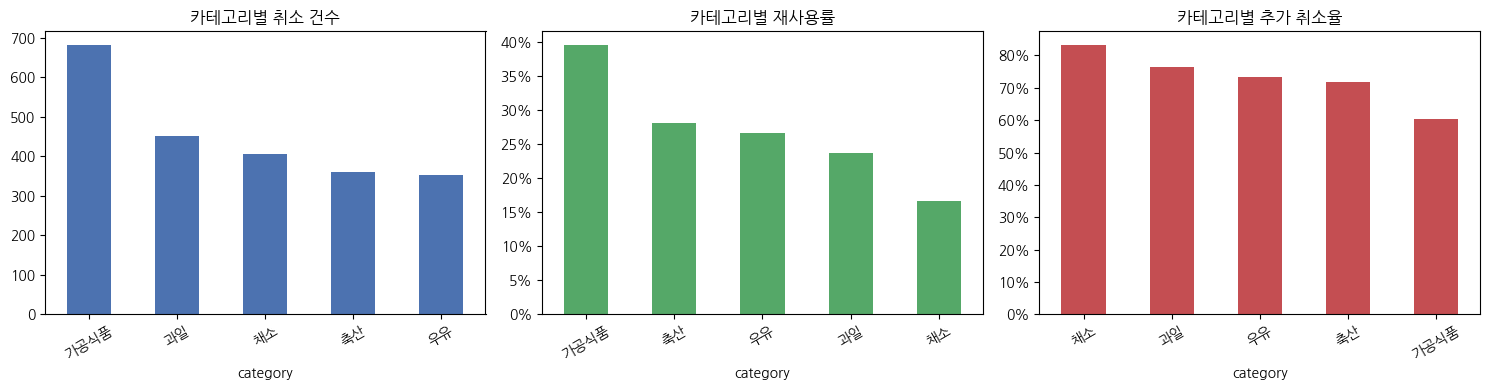

In [ ]:
# =============================================
# STEP 10: 4단계 분석 — 카테고리 분석
# =============================================

cat_count  = op_df.groupby('category')['cancel_reason'].count().sort_values(ascending=False)
cat_reuse  = op_df.groupby('category')['reused_flag'].mean().sort_values(ascending=False)
cat_addcan = op_df.groupby('category')['additional_cancel_flag'].mean().sort_values(ascending=False)

print("=" * 45)
print("4단계. 카테고리 분석")
print("=" * 45)
print("\n[ 카테고리별 운영 취소 건수 ]")
print(cat_count)
print("\n[ 카테고리별 재사용률 ]")
print(cat_reuse.round(3))
print("\n[ 카테고리별 추가 취소율 ]")
print(cat_addcan.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cat_count.plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('카테고리별 취소 건수')
axes[0].tick_params(axis='x', rotation=30)

cat_reuse.plot(kind='bar', ax=axes[1], color='#55A868')
axes[1].set_title('카테고리별 재사용률')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].tick_params(axis='x', rotation=30)

cat_addcan.plot(kind='bar', ax=axes[2], color='#C44E52')
axes[2].set_title('카테고리별 추가 취소율')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## **STEP11 - 5단계 분석**

5단계. 운영 개선 시뮬레이션 (수동 vs 자동화)
         지표 수동 처리 (기존) 자동화 처리 (개선)
       재사용률      28.4%       36.9%
     추가 취소율      71.6%       63.1%
평균 탐색 대기(분)       34.9         0.0
평균 탐색 시간(분)      37.33        0.59
평균 처리 지연(분)       35.7         0.3

[수동 사유별 재사용률]
cancel_reason
리빈파손    0.000
미집      0.260
오집      0.370
집품파손    0.000
토트분실    0.117
Name: reused_flag, dtype: float64

[자동화 사유별 재사용률]
cancel_reason
리빈파손    0.000
미집      0.335
오집      0.481
집품파손    0.000
토트분실    0.152
Name: reused_flag, dtype: float64

[수동 사유별 추가취소율]
cancel_reason
리빈파손    1.000
미집      0.740
오집      0.630
집품파손    1.000
토트분실    0.883
Name: additional_cancel_flag, dtype: float64

[자동화 사유별 추가취소율]
cancel_reason
리빈파손    1.000
미집      0.665
오집      0.519
집품파손    1.000
토트분실    0.848
Name: additional_cancel_flag, dtype: float64


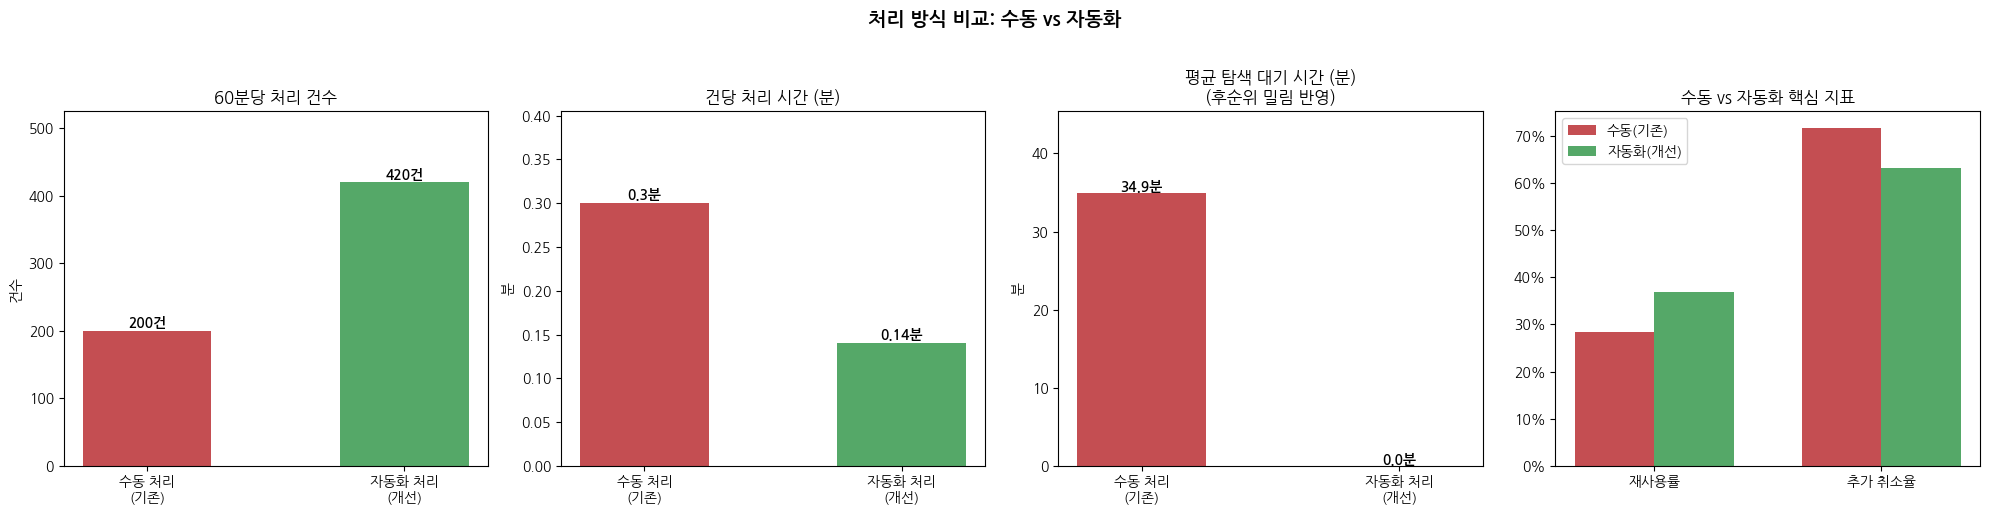

In [ ]:
# =============================================
# STEP 11: 5단계 분석 — 운영 개선 시뮬레이션
# =============================================

# 자동화 처리 방식 설정
# [수정] 셀 단위 시드 고정 — 셀 재실행 순서와 무관하게 동일 결과 보장
random.seed(52)
np.random.seed(52)

improved_df = op_df.copy()

improved_df = assign_process_time_by_queue(
    improved_df,
    time_per_case=AUTOMATED_TIME_PER_CASE,
    process_type='automated',
    batch_range=(30, 50),
    break_range=(0, 0)
)

# 개선 가정 2: 전산화로 위치 정보 확인 가능 비율 95%
improved_df['location_known'] = [
    1 if random.random() < 0.95 else 0
    for _ in range(len(improved_df))
]

# ============================================================
# 1) restock_flag 재계산
#    자동화로 지연시간이 줄었으므로 재고 반영 여부도 다시 계산해야 함
# ============================================================
improved_df['restock_flag'] = improved_df.apply(decide_restock, axis=1)

# ============================================================
# 2) 자동화 기준 오집 재고 풀 재생성
#    미집/토트분실 대체 재사용 판단에 사용할 풀
# ============================================================
wrong_pick_pool_improved = (
    improved_df[
        (improved_df['cancel_reason'] == '오집') &
        (improved_df['restock_flag'] == 1)
    ]
    .groupby(['product_id', 'sku_option'])
    .size()
    .reset_index(name='available_count')
)

# ============================================================
# 3) inspection_flag 재계산
# ============================================================
def inspection_improved(row):
    if row['cancel_reason'] not in ['오집', '미집', '토트분실']:
        return 0

    if row['cancel_reason'] == '오집' and row['restock_flag'] == 0:
        return 0

    return 1 if random.random() < 0.90 else 0

improved_df['inspection_flag'] = improved_df.apply(inspection_improved, axis=1)

# ============================================================
# 4) reused_flag 재계산
# ============================================================
def reuse_improved(row):
    if row['cancel_reason'] in ['단순취소', '집품파손', '리빈파손']:
        return 0

    # 오집: 재고 반영 + 자동화 검수 통과 후 재사용 가능
    if row['cancel_reason'] == '오집':
        if row['restock_flag'] == 0:
            return 0

        if row['inspection_flag'] == 0:
            return 0

        base = REUSE_PROB.get(row['category'], 0.50)

        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.70

        return 1 if random.random() < base else 0

    # 미집/토트분실: 오집 재고 풀에서 동일 SKU 탐색 후 대체 재사용
    if row['cancel_reason'] in ['미집', '토트분실']:
        if row['inspection_flag'] == 0:
            return 0

        matched = wrong_pick_pool_improved[
            (wrong_pick_pool_improved['product_id'] == row['product_id']) &
            (wrong_pick_pool_improved['sku_option'] == row['sku_option'])
        ]

        if len(matched) == 0:
            return 0

        if row['cancel_reason'] == '미집':
            base = 0.7
        else:
            base = 0.3

        if row['process_delay_min'] > DELAY_THRESHOLD_MIN:
            base *= 0.70

        return 1 if random.random() < base else 0

    return 0

improved_df['reused_flag'] = improved_df.apply(reuse_improved, axis=1)

# ============================================================
# 5) additional_cancel_flag 재계산
#    재사용 성공 시 추가 취소 0
# ============================================================
def add_cancel_improved(row):
    """
    개선 후에도 재사용 가능 사유에서 재사용 실패한 건을
    추가 취소로 간주한다.
    """

    if row['cancel_reason'] == '단순취소':
        return 0

    if row['cancel_reason'] in ['집품파손','리빈파손']:
        return 1


    if row['cancel_reason'] in ['오집', '미집', '토트분실']:
        return 1 if row['reused_flag'] == 0 else 0

    return 0

improved_df['additional_cancel_flag'] = improved_df.apply(add_cancel_improved, axis=1)

# ============================================================
# 6) search_time 재계산
# ============================================================
result = improved_df.apply(calc_search, axis=1)

improved_df['search_start_time'] = [r[0] for r in result]
improved_df['search_end_time']   = [r[1] for r in result]
improved_df['search_time_min']   = [r[2] for r in result]
improved_df['search_wait_min']   = [r[3] for r in result]

# ── 개선 전/후 비교 테이블 ────────────────────
before = op_df
after  = improved_df

compare = pd.DataFrame({
    '지표': [
        '재사용률',
        '추가 취소율',
        '평균 탐색 대기(분)',
        '평균 탐색 시간(분)',
        '평균 처리 지연(분)',
    ],
    '수동 처리 (기존)': [
        f"{before['reused_flag'].mean():.1%}",
        f"{before['additional_cancel_flag'].mean():.1%}",
        f"{before['search_wait_min'].dropna().mean():.1f}",
        f"{before['search_time_min'].dropna().mean():.2f}",
        f"{before['process_delay_min'].mean():.1f}",
    ],
    '자동화 처리 (개선)': [
        f"{after['reused_flag'].mean():.1%}",
        f"{after['additional_cancel_flag'].mean():.1%}",
        f"{after['search_wait_min'].dropna().mean():.1f}",
        f"{after['search_time_min'].dropna().mean():.2f}",
        f"{after['process_delay_min'].mean():.1f}",
    ],
})

print("=" * 58)
print("5단계. 운영 개선 시뮬레이션 (수동 vs 자동화)")
print("=" * 58)
print(compare.to_string(index=False))

# 디버깅용: 사유별 비교
print("\n[수동 사유별 재사용률]")
print(before.groupby('cancel_reason')['reused_flag'].mean().round(3))

print("\n[자동화 사유별 재사용률]")
print(after.groupby('cancel_reason')['reused_flag'].mean().round(3))

print("\n[수동 사유별 추가취소율]")
print(before.groupby('cancel_reason')['additional_cancel_flag'].mean().round(3))

print("\n[자동화 사유별 추가취소율]")
print(after.groupby('cancel_reason')['additional_cancel_flag'].mean().round(3))

# ── 시각화 ────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

labels = ['수동 처리\n(기존)', '자동화 처리\n(개선)']

# 차트 1: 60분당 처리 건수
speed_vals = [MANUAL_THROUGHPUT, AUTOMATED_THROUGHPUT]
bars = axes[0].bar(labels, speed_vals, color=['#C44E52', '#55A868'], width=0.5)
axes[0].set_title('60분당 처리 건수', fontsize=12)
axes[0].set_ylabel('건수')
for bar, val in zip(bars, speed_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{val}건', ha='center', fontweight='bold')
axes[0].set_ylim(0, max(speed_vals) * 1.25)

# 차트 2: 건당 처리 시간
time_vals = [MANUAL_TIME_PER_CASE, AUTOMATED_TIME_PER_CASE]
bars2 = axes[1].bar(labels, time_vals, color=['#C44E52', '#55A868'], width=0.5)
axes[1].set_title('건당 처리 시간 (분)', fontsize=12)
axes[1].set_ylabel('분')
for bar, val in zip(bars2, time_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val}분', ha='center', fontweight='bold')
axes[1].set_ylim(0, max(time_vals) * 1.35)

# 차트 3: 평균 탐색 대기 시간
wait_vals = [
    before['search_wait_min'].dropna().mean(),
    after['search_wait_min'].dropna().mean(),
]
bars3 = axes[2].bar(labels, wait_vals, color=['#C44E52', '#55A868'], width=0.5)
axes[2].set_title('평균 탐색 대기 시간 (분)\n(후순위 밀림 반영)', fontsize=12)
axes[2].set_ylabel('분')
for bar, val in zip(bars3, wait_vals):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}분', ha='center', fontweight='bold')
axes[2].set_ylim(0, max(wait_vals) * 1.3 if max(wait_vals) > 0 else 5)

# 차트 4: 재사용률 & 추가취소율 비교
metrics = ['재사용률', '추가 취소율']
before_vals = [
    before['reused_flag'].mean(),
    before['additional_cancel_flag'].mean()
]
after_vals = [
    after['reused_flag'].mean(),
    after['additional_cancel_flag'].mean()
]

x = range(len(metrics))
w = 0.35

axes[3].bar([i - w/2 for i in x], before_vals, width=w, label='수동(기존)', color='#C44E52')
axes[3].bar([i + w/2 for i in x], after_vals, width=w, label='자동화(개선)', color='#55A868')
axes[3].set_title('수동 vs 자동화 핵심 지표', fontsize=12)
axes[3].set_xticks(list(x))
axes[3].set_xticklabels(metrics)
axes[3].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[3].legend()

plt.suptitle('처리 방식 비교: 수동 vs 자동화', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

STEP 11-3. 검색 매칭 성공률 비교
                개선 전   개선 후
cancel_reason              
미집             0.497  0.552
토트분실           0.507  0.552


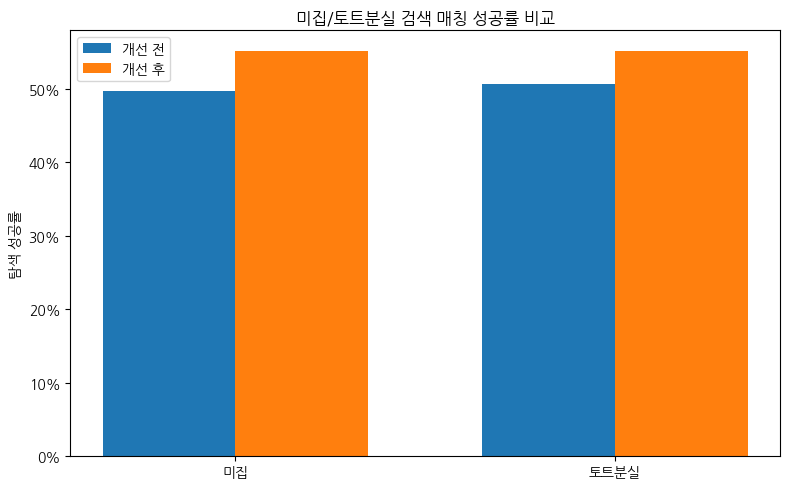

In [ ]:
# =============================================
# STEP 11-3: 검색 매칭 성공률 비교
# =============================================

# [수정] 셀 단위 시드 고정 — 셀 재실행 순서와 무관하게 동일 결과 보장
random.seed(53)
np.random.seed(53)

target_reasons = ['미집', '토트분실']

# 개선 전
before_match_df = op_df[
    op_df['cancel_reason'].isin(target_reasons)
].copy()

# 개선 후
after_match_df = improved_df[
    improved_df['cancel_reason'].isin(target_reasons)
].copy()


# 실제 일치 상품 존재 여부 확인 함수
def has_pool_match(row, pool):
    matched = pool[
        (pool['product_id'] == row['product_id']) &
        (pool['sku_option'] == row['sku_option'])
    ]
    return 1 if len(matched) > 0 else 0


# 개선 전: 실제 매칭 존재 여부
before_match_df['pool_match_flag'] = before_match_df.apply(
    lambda r: has_pool_match(r, wrong_pick_pool),
    axis=1
)

# 개선 후: 실제 매칭 존재 여부
after_match_df['pool_match_flag'] = after_match_df.apply(
    lambda r: has_pool_match(r, wrong_pick_pool_improved),
    axis=1
)


# 개선 전: 수동 탐색 성공 여부
before_match_df['search_match_success_flag'] = (
    before_match_df['pool_match_flag'].apply(
        lambda x: 1 if x == 1 and random.random() >= MANUAL_MATCH_MISS_PROB else 0
    )
)

# 개선 후: 검색모듈 적용 → 매칭 존재 시 100% 탐색 성공
after_match_df['search_match_success_flag'] = (
    after_match_df['pool_match_flag']
)


# 사유별 탐색 성공률
before_match_rate = (
    before_match_df.groupby('cancel_reason')['search_match_success_flag']
    .mean()
)

after_match_rate = (
    after_match_df.groupby('cancel_reason')['search_match_success_flag']
    .mean()
)


# 비교용 DataFrame
match_compare = pd.DataFrame({
    '개선 전': before_match_rate,
    '개선 후': after_match_rate
})


print("=" * 60)
print("STEP 11-3. 검색 매칭 성공률 비교")
print("=" * 60)

print(match_compare.round(3))


# =============================================
# 시각화
# =============================================

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(match_compare.index))
width = 0.35

ax.bar(
    x - width/2,
    match_compare['개선 전'],
    width,
    label='개선 전'
)

ax.bar(
    x + width/2,
    match_compare['개선 후'],
    width,
    label='개선 후'
)

ax.set_title('미집/토트분실 검색 매칭 성공률 비교')
ax.set_ylabel('탐색 성공률')

ax.set_xticks(x)
ax.set_xticklabels(match_compare.index)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f'{y:.0%}')
)

ax.legend()

plt.tight_layout()
plt.show()

## **STEP12 - 월별 / 연간 개선 효과 추청**

STEP 12. 월별 / 연간 개선 효과 추정

[ 월별 개선 효과 ]
 month  days  daily_orders  estimated_orders  expected_op_cancel  before_add_cancel_count  after_add_cancel_count  reduced_add_cancel_count  before_reuse_count  after_reuse_count  increased_reuse_count
     1    31        148118           4591658               68874                    49317                   43481                      5836               19556              25392                   5836
     2    28        163727           4584356               68765                    49239                   43412                      5827               19525              25352                   5827
     3    31        167122           5180782               77711                    55645                   49060                      6585               22065              28650                   6585
     4    30        171677           5150310               77254                    55318                   48772                      6546             

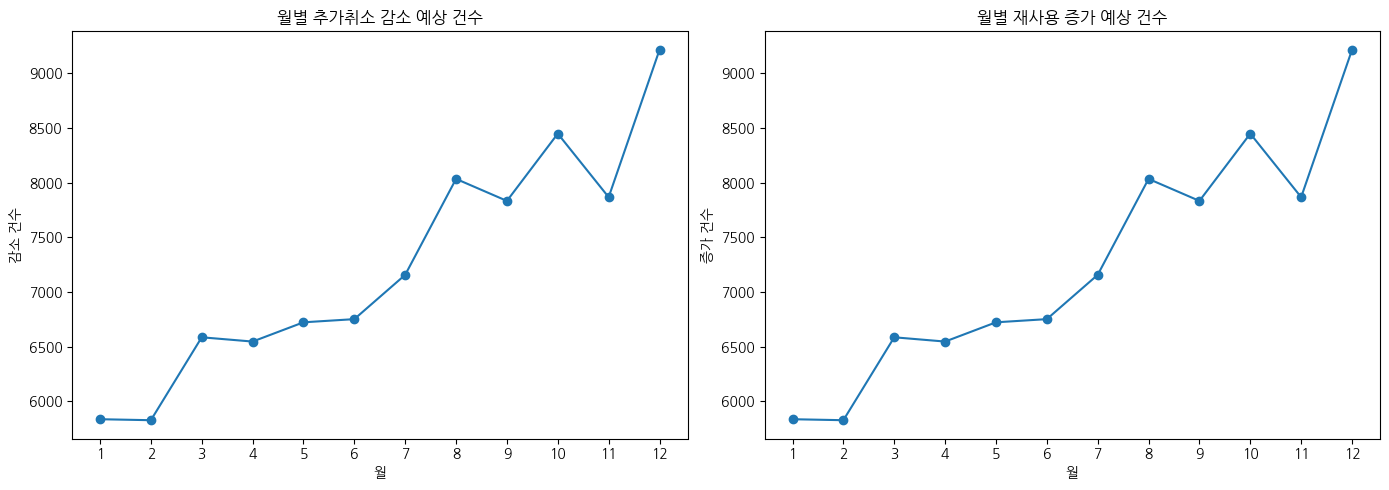

In [ ]:
# =============================================
# STEP 12: 월별 / 연간 개선 효과 추정
# =============================================

# STEP 1의 N_ORDERS는 "일 평균 주문량"으로 해석
base_daily_orders = N_ORDERS   # 예: 150,000건/일

# 월별 일수
days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# 주문물량 증가 가정
# 3개월마다 일 주문량이 20,000건씩 증가한다고 가정
quarterly_daily_order_increase = 20000

# 월 단위 완만 증가
monthly_daily_growth = quarterly_daily_order_increase / 3

# 주문량 자체 변동성: ±5%
ORDER_VOLUME_ERROR_RATE = 0.05

# 개선 전/후 추가취소율
before_add_cancel_rate = before['additional_cancel_flag'].mean()
after_add_cancel_rate = after['additional_cancel_flag'].mean()

# 개선 전/후 재사용률
before_reuse_rate = before['reused_flag'].mean()
after_reuse_rate = after['reused_flag'].mean()

# 전체 주문 대비 운영취소 발생률
# 기존 방식보다 해석이 명확한 방식
op_cancel_rate = CANCEL_RATE * CANCEL_TYPE_WEIGHTS['운영취소']

# 월별 추정
np.random.seed(42)
monthly_results = []

for month in range(1, 13):
    # 월별 일 평균 주문량
    daily_orders = base_daily_orders + ((month - 1) * monthly_daily_growth)

    # 주문량 오차 부여
    order_volume_multiplier = np.random.uniform(
        1 - ORDER_VOLUME_ERROR_RATE,
        1 + ORDER_VOLUME_ERROR_RATE
    )

    daily_orders_adj = int(daily_orders * order_volume_multiplier)

    # 월 주문량 = 일 평균 주문량 × 해당 월 일수
    monthly_orders_adj = int(daily_orders_adj * days_in_month[month - 1])

    # 월별 운영취소 예상 건수
    expected_op_cancel = int(monthly_orders_adj * op_cancel_rate)

    # 개선 전/후 추가취소 예상 건수
    before_add_cancel_count = int(expected_op_cancel * before_add_cancel_rate)
    after_add_cancel_count = int(expected_op_cancel * after_add_cancel_rate)

    # 개선 전/후 재사용 예상 건수
    before_reuse_count = int(expected_op_cancel * before_reuse_rate)
    after_reuse_count = int(expected_op_cancel * after_reuse_rate)

    # 개선 효과
    reduced_add_cancel_count = before_add_cancel_count - after_add_cancel_count
    increased_reuse_count = after_reuse_count - before_reuse_count

    monthly_results.append({
        'month': month,
        'days': days_in_month[month - 1],
        'daily_orders': daily_orders_adj,
        'estimated_orders': monthly_orders_adj,
        'expected_op_cancel': expected_op_cancel,

        'before_add_cancel_count': before_add_cancel_count,
        'after_add_cancel_count': after_add_cancel_count,
        'reduced_add_cancel_count': reduced_add_cancel_count,

        'before_reuse_count': before_reuse_count,
        'after_reuse_count': after_reuse_count,
        'increased_reuse_count': increased_reuse_count,
    })

monthly_effect_df = pd.DataFrame(monthly_results)

# 연간 합계
annual_summary = pd.DataFrame({
    '지표': [
        '연간 예상 주문 수',
        '연간 예상 운영취소 건수',
        '개선 전 추가취소 건수',
        '개선 후 추가취소 건수',
        '연간 추가취소 감소 건수',
        '개선 전 재사용 성공 건수',
        '개선 후 재사용 성공 건수',
        '연간 재사용 증가 건수',
    ],
    '값': [
        monthly_effect_df['estimated_orders'].sum(),
        monthly_effect_df['expected_op_cancel'].sum(),
        monthly_effect_df['before_add_cancel_count'].sum(),
        monthly_effect_df['after_add_cancel_count'].sum(),
        monthly_effect_df['reduced_add_cancel_count'].sum(),
        monthly_effect_df['before_reuse_count'].sum(),
        monthly_effect_df['after_reuse_count'].sum(),
        monthly_effect_df['increased_reuse_count'].sum(),
    ]
})

print("=" * 60)
print("STEP 12. 월별 / 연간 개선 효과 추정")
print("=" * 60)

print("\n[ 월별 개선 효과 ]")
print(monthly_effect_df.to_string(index=False))

print("\n[ 연간 개선 효과 요약 ]")
print(annual_summary.to_string(index=False))

# STEP 11과 동일한 기준: 비율 차이(%p)
add_cancel_reduction_pp = before_add_cancel_rate - after_add_cancel_rate
reuse_increase_pp = after_reuse_rate - before_reuse_rate

print("\n[ 연간 개선폭 - STEP 11과 동일 기준 ]")
print(f"추가취소율 감소폭 : {add_cancel_reduction_pp * 100:.2f}%p")
print(f"재사용률 증가폭   : {reuse_increase_pp * 100:.2f}%p")


# =============================================
# STEP 12 시각화
# =============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1) 월별 추가취소 감소 건수
axes[0].plot(
    monthly_effect_df['month'],
    monthly_effect_df['reduced_add_cancel_count'],
    marker='o'
)
axes[0].set_title('월별 추가취소 감소 예상 건수')
axes[0].set_xlabel('월')
axes[0].set_ylabel('감소 건수')
axes[0].set_xticks(range(1, 13))

# 2) 월별 재사용 증가 건수
axes[1].plot(
    monthly_effect_df['month'],
    monthly_effect_df['increased_reuse_count'],
    marker='o'
)
axes[1].set_title('월별 재사용 증가 예상 건수')
axes[1].set_xlabel('월')
axes[1].set_ylabel('증가 건수')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

## **STEP13 - 저장**

In [ ]:
# =============================================
# STEP 13: 저장
# =============================================
from google.colab import drive
drive.mount('/content/drive')

import os
PATH = '/content/drive/MyDrive/logistics_simulation/'
# TODO: 원하는 드라이브 경로로 변경
os.makedirs(PATH, exist_ok=True)

final_df.to_csv(PATH + 'simulation_data.csv',       index=False, encoding='utf-8-sig')
improved_df.to_csv(PATH + 'simulation_improved.csv', index=False, encoding='utf-8-sig')
print(f"저장 완료 → {PATH}")
print(f"simulation_data.csv    : {len(final_df):,}행")
print(f"simulation_improved.csv: {len(improved_df):,}행")

Mounted at /content/drive
저장 완료 → /content/drive/MyDrive/logistics_simulation/
simulation_data.csv    : 7,500행
simulation_improved.csv: 2,254행


**시뮬레이션 데이터 기반이며 실제 운영 데이터 적용 시 수치는 달라질 수 있다**

# **운영데이터 흐름 개선용 분석**

## **STEP14 - 취소 기록 기반 오집,미집 고위험 구간 탐지**

In [ ]:
# =============================================
# STEP 14: 1시간 단위 오집·미집 이상 로케이션 탐지
# - 기존 final_df를 변경하지 않고 확장 분석용 데이터 생성
# =============================================

hourly_df = improved_df.copy()

# 운영취소만 분석
hourly_df = hourly_df[hourly_df['cancel_reason'] != '단순취소'].copy()

# 오집/미집 여부
hourly_df['error_flag'] = hourly_df['cancel_reason'].isin(['오집', '미집']).astype(int)
hourly_df['wrong_pick_flag'] = (hourly_df['cancel_reason'] == '오집').astype(int)
hourly_df['missing_pick_flag'] = (hourly_df['cancel_reason'] == '미집').astype(int)

# 로케이션 구역
hourly_df['stock_zone'] = (
    hourly_df['stock_location']
    .astype(str)
    .str.split('-')
    .str[0]
)

# 시간 단위 구간 생성
hourly_df['cancel_hour'] = hourly_df['cancel_time'].dt.floor('h')  # [수정] pandas 2.2+ 호환: 'H' → 'h'

print("=" * 60)
print("STEP 14. 1시간 단위 오집·미집 이상 로케이션 탐지")
print("=" * 60)
print(f"운영취소 건수: {len(hourly_df):,}건")
print(f"오집·미집 건수: {hourly_df['error_flag'].sum():,}건")
print(f"분석 시간 구간 수: {hourly_df['cancel_hour'].nunique():,}개")
print(f"분석 로케이션 구역 수: {hourly_df['stock_zone'].nunique():,}개")

STEP 14. 1시간 단위 오집·미집 이상 로케이션 탐지
운영취소 건수: 2,254건
오집·미집 건수: 1,823건
분석 시간 구간 수: 16개
분석 로케이션 구역 수: 5개


In [ ]:
# =============================================
# STEP 14-1: 시간 × 로케이션별 오집·미집 집계
# =============================================

hour_location_summary = (
    hourly_df
    .groupby(['cancel_hour', 'stock_zone'])
    .agg(
        total_op_cancel=('order_id', 'count'),
        error_count=('error_flag', 'sum'),
        wrong_pick_count=('wrong_pick_flag', 'sum'),
        missing_pick_count=('missing_pick_flag', 'sum'),
        additional_cancel_count=('additional_cancel_flag', 'sum'),
        additional_cancel_rate=('additional_cancel_flag', 'mean')
    )
    .reset_index()
)

hour_location_summary['error_rate'] = (
    hour_location_summary['error_count'] /
    hour_location_summary['total_op_cancel']
)

# 시간대별 평균/표준편차 대비 이상치 판단
hour_stats = (
    hour_location_summary
    .groupby('cancel_hour')
    .agg(
        hour_avg_error_count=('error_count', 'mean'),
        hour_std_error_count=('error_count', 'std'),
        hour_avg_error_rate=('error_rate', 'mean'),
        hour_std_error_rate=('error_rate', 'std')
    )
    .reset_index()
)

hour_location_summary = hour_location_summary.merge(
    hour_stats,
    on='cancel_hour',
    how='left'
)

# 표준편차가 0 또는 NaN인 경우 보정
hour_location_summary['hour_std_error_count'] = (
    hour_location_summary['hour_std_error_count']
    .fillna(0)
)

hour_location_summary['hour_std_error_rate'] = (
    hour_location_summary['hour_std_error_rate']
    .fillna(0)
)

# 이상치 기준:
# 1. 해당 시간 평균 오류 건수보다 많고
# 2. 평균 + 1표준편차 이상이거나, 오류율이 시간 평균보다 높고
# 3. 최소 오류 건수 2건 이상
MIN_HOURLY_ERROR_COUNT = 2

hour_location_summary['is_outlier_location'] = (
    (
        hour_location_summary['error_count'] >=
        hour_location_summary['hour_avg_error_count'] + hour_location_summary['hour_std_error_count']
    ) |
    (
        hour_location_summary['error_rate'] >=
        hour_location_summary['hour_avg_error_rate'] + hour_location_summary['hour_std_error_rate']
    )
) & (
    hour_location_summary['error_count'] >= MIN_HOURLY_ERROR_COUNT
)

outlier_locations = hour_location_summary[
    hour_location_summary['is_outlier_location']
].copy()

outlier_locations = outlier_locations.sort_values(
    ['cancel_hour', 'error_count', 'error_rate'],
    ascending=[True, False, False]
)

print("=" * 60)
print("시간별 이상 로케이션 탐지 결과")
print("=" * 60)
print(f"이상 로케이션 감지 건수: {len(outlier_locations):,}건")

print(outlier_locations[
    [
        'cancel_hour',
        'stock_zone',
        'total_op_cancel',
        'error_count',
        'wrong_pick_count',
        'missing_pick_count',
        'error_rate',
        'hour_avg_error_count',
        'hour_std_error_count',
        'additional_cancel_rate'
    ]
].round(3).head(20))

시간별 이상 로케이션 탐지 결과
이상 로케이션 감지 건수: 22건
           cancel_hour stock_zone  total_op_cancel  error_count  \
2  2024-01-01 08:00:00          C               16           14   
3  2024-01-01 08:00:00          D               14           13   
7  2024-01-01 09:00:00          C               14           11   
10 2024-01-01 10:00:00          A               34           28   
11 2024-01-01 10:00:00          B               19           17   
16 2024-01-01 11:00:00          B               37           30   
21 2024-01-01 12:00:00          B               49           44   
26 2024-01-01 13:00:00          B               39           31   
29 2024-01-01 13:00:00          E               33           29   
30 2024-01-01 14:00:00          A               20           19   
35 2024-01-01 15:00:00          A               37           33   
39 2024-01-01 15:00:00          E               26           24   
44 2024-01-01 16:00:00          E               42           36   
47 2024-01-01 17:00:00   

In [ ]:
# =============================================
# STEP 14-2: 이상 로케이션 교육 스케줄 생성
# - 이상 탐지 시간의 다음 1시간에 개선 효과가 발생한다고 가정
# =============================================

training_schedule = outlier_locations[
    ['cancel_hour', 'stock_zone', 'error_count', 'error_rate']
].copy()

training_schedule['training_hour'] = training_schedule['cancel_hour']
training_schedule['effect_hour'] = training_schedule['cancel_hour'] + pd.Timedelta(hours=1)

training_schedule = training_schedule.rename(columns={
    'cancel_hour': 'detected_hour',
    'error_count': 'detected_error_count',
    'error_rate': 'detected_error_rate'
})

print("=" * 60)
print("1시간 단위 교육/피드백 스케줄")
print("=" * 60)
print(training_schedule.head(20))

1시간 단위 교육/피드백 스케줄
         detected_hour stock_zone  detected_error_count  detected_error_rate  \
2  2024-01-01 08:00:00          C                    14             0.875000   
3  2024-01-01 08:00:00          D                    13             0.928571   
7  2024-01-01 09:00:00          C                    11             0.785714   
10 2024-01-01 10:00:00          A                    28             0.823529   
11 2024-01-01 10:00:00          B                    17             0.894737   
16 2024-01-01 11:00:00          B                    30             0.810811   
21 2024-01-01 12:00:00          B                    44             0.897959   
26 2024-01-01 13:00:00          B                    31             0.794872   
29 2024-01-01 13:00:00          E                    29             0.878788   
30 2024-01-01 14:00:00          A                    19             0.950000   
35 2024-01-01 15:00:00          A                    33             0.891892   
39 2024-01-01 15:00:00

## **STEP15 - 재교육 효과 시나리오**

In [ ]:
# =============================================
# STEP 15: 다음 시간 개선 효과 시뮬레이션
# - 교육 대상 로케이션은 다음 시간 오집·미집이 10% 감소한다고 가정
# =============================================

TRAINING_EFFECT = 0.10

# 다음 시간 효과 적용 대상 추출
effect_targets = training_schedule[
    ['effect_hour', 'stock_zone']
].drop_duplicates()

effect_target_df = hourly_df.merge(
    effect_targets,
    left_on=['cancel_hour', 'stock_zone'],
    right_on=['effect_hour', 'stock_zone'],
    how='inner'
).copy()

# 효과 대상 중 오집·미집 건만 개선 가능
effect_error_df = effect_target_df[
    effect_target_df['error_flag'] == 1
].copy()

current_total_op_cancel = len(hourly_df)
current_error_count = int(hourly_df['error_flag'].sum())
current_add_cancel_count = int(hourly_df['additional_cancel_flag'].sum())
current_add_cancel_rate = hourly_df['additional_cancel_flag'].mean()

target_next_hour_error_count = len(effect_error_df)
prevented_error_count = target_next_hour_error_count * TRAINING_EFFECT

# 오집·미집 중 추가취소로 이어진 비율만큼 추가취소 감소
target_error_add_cancel_rate = effect_error_df['additional_cancel_flag'].mean()
reduced_add_cancel_count = prevented_error_count * target_error_add_cancel_rate

# 교육 효과 반영 후
after_total_op_cancel = current_total_op_cancel - prevented_error_count
after_error_count = current_error_count - prevented_error_count
after_add_cancel_count = current_add_cancel_count - reduced_add_cancel_count

after_error_rate = after_error_count / after_total_op_cancel
after_add_cancel_rate = after_add_cancel_count / after_total_op_cancel

hourly_training_effect = pd.DataFrame({
    '지표': [
        '운영취소 건수',
        '오집·미집 건수',
        '운영취소 내 오집·미집 비중',
        '추가취소 건수',
        '추가취소율'
    ],
    '교육 전': [
        current_total_op_cancel,
        current_error_count,
        current_error_count / current_total_op_cancel,
        current_add_cancel_count,
        current_add_cancel_rate
    ],
    '교육 후 예상': [
        after_total_op_cancel,
        after_error_count,
        after_error_rate,
        after_add_cancel_count,
        after_add_cancel_rate
    ],
    '개선 효과': [
        current_total_op_cancel - after_total_op_cancel,
        current_error_count - after_error_count,
        (current_error_count / current_total_op_cancel) - after_error_rate,
        current_add_cancel_count - after_add_cancel_count,
        current_add_cancel_rate - after_add_cancel_rate
    ]
})

print("=" * 60)
print("STEP 15. 시간 단위 교육 후 다음 시간 개선 효과")
print("=" * 60)
print(f"교육/피드백 발생 건수: {len(training_schedule):,}건")
print(f"다음 시간 효과 적용 대상 오집·미집 건수: {target_next_hour_error_count:,}건")
print(f"오집·미집 감소 가정: {TRAINING_EFFECT:.0%}")
print(f"예상 예방 오집·미집 건수: {prevented_error_count:,.1f}건")
print(f"예상 추가취소 감소 건수: {reduced_add_cancel_count:,.1f}건")

print("\n[교육 전후 기대효과]")
print(hourly_training_effect)

STEP 15. 시간 단위 교육 후 다음 시간 개선 효과
교육/피드백 발생 건수: 22건
다음 시간 효과 적용 대상 오집·미집 건수: 501건
오집·미집 감소 가정: 10%
예상 예방 오집·미집 건수: 50.1건
예상 추가취소 감소 건수: 29.1건

[교육 전후 기대효과]
                지표         교육 전      교육 후 예상      개선 효과
0          운영취소 건수  2254.000000  2203.900000  50.100000
1         오집·미집 건수  1823.000000  1772.900000  50.100000
2  운영취소 내 오집·미집 비중     0.808784     0.804438   0.004347
3          추가취소 건수  1423.000000  1393.900000  29.100000
4            추가취소율     0.631322     0.632470  -0.001148


In [ ]:
# =============================================
# STEP 15-1: 교육 효과 민감도 분석
# =============================================

effect_scenarios = [0.10, 0.20, 0.30]
scenario_results = []

for effect in effect_scenarios:
    prevented_errors = target_next_hour_error_count * effect
    reduced_add_cancels = prevented_errors * target_error_add_cancel_rate

    new_total_op_cancel = current_total_op_cancel - prevented_errors
    new_error_count = current_error_count - prevented_errors
    new_add_cancel_count = current_add_cancel_count - reduced_add_cancels

    new_error_rate = new_error_count / new_total_op_cancel
    new_add_cancel_rate = new_add_cancel_count / new_total_op_cancel

    scenario_results.append({
        '다음 시간 오집·미집 감소 가정': f'{effect:.0%}',
        '예상 예방 오집·미집 건수': prevented_errors,
        '예상 추가취소 감소 건수': reduced_add_cancels,
        '교육 후 오집·미집 비중': new_error_rate,
        '교육 후 추가취소율': new_add_cancel_rate,
        '추가취소율 개선폭': current_add_cancel_rate - new_add_cancel_rate
    })

hourly_scenario_df = pd.DataFrame(scenario_results)

print("=" * 60)
print("시간 단위 교육 효과 민감도 분석")
print("=" * 60)
print(hourly_scenario_df.round(4))

시간 단위 교육 효과 민감도 분석
  다음 시간 오집·미집 감소 가정  예상 예방 오집·미집 건수  예상 추가취소 감소 건수  교육 후 오집·미집 비중  교육 후 추가취소율  \
0               10%            50.1           29.1         0.8044      0.6325   
1               20%           100.2           58.2         0.7999      0.6337   
2               30%           150.3           87.3         0.7951      0.6349   

   추가취소율 개선폭  
0    -0.0011  
1    -0.0023  
2    -0.0036  


In [ ]:
# =============================================
# STEP 15-2: 시간별 교육 효과 추적 테이블
# =============================================

# 효과 대상 시간 × 로케이션별 실제 다음 시간 오집·미집 집계
effect_hour_summary = (
    effect_target_df
    .groupby(['cancel_hour', 'stock_zone'])
    .agg(
        next_hour_total_op_cancel=('order_id', 'count'),
        next_hour_error_count=('error_flag', 'sum'),
        next_hour_add_cancel_count=('additional_cancel_flag', 'sum')
    )
    .reset_index()
)

effect_hour_summary['expected_prevented_error_count'] = (
    effect_hour_summary['next_hour_error_count'] * TRAINING_EFFECT
)

effect_hour_summary['expected_reduced_add_cancel_count'] = (
    effect_hour_summary['expected_prevented_error_count'] *
    target_error_add_cancel_rate
)

effect_hour_summary = effect_hour_summary.sort_values(
    ['cancel_hour', 'expected_prevented_error_count'],
    ascending=[True, False]
)

print("=" * 60)
print("시간별/로케이션별 다음 시간 개선 효과 추정")
print("=" * 60)

print(effect_hour_summary.round(3).head(30))

시간별/로케이션별 다음 시간 개선 효과 추정
           cancel_hour stock_zone  next_hour_total_op_cancel  \
1  2024-01-01 09:00:00          D                         19   
0  2024-01-01 09:00:00          C                         14   
2  2024-01-01 10:00:00          C                         28   
4  2024-01-01 11:00:00          B                         37   
3  2024-01-01 11:00:00          A                         32   
5  2024-01-01 12:00:00          B                         49   
6  2024-01-01 13:00:00          B                         39   
7  2024-01-01 14:00:00          B                         33   
8  2024-01-01 14:00:00          E                         31   
9  2024-01-01 15:00:00          A                         37   
11 2024-01-01 16:00:00          E                         42   
10 2024-01-01 16:00:00          A                         27   
12 2024-01-01 17:00:00          E                         42   
13 2024-01-01 18:00:00          C                         38   
14 2024-01-01 2

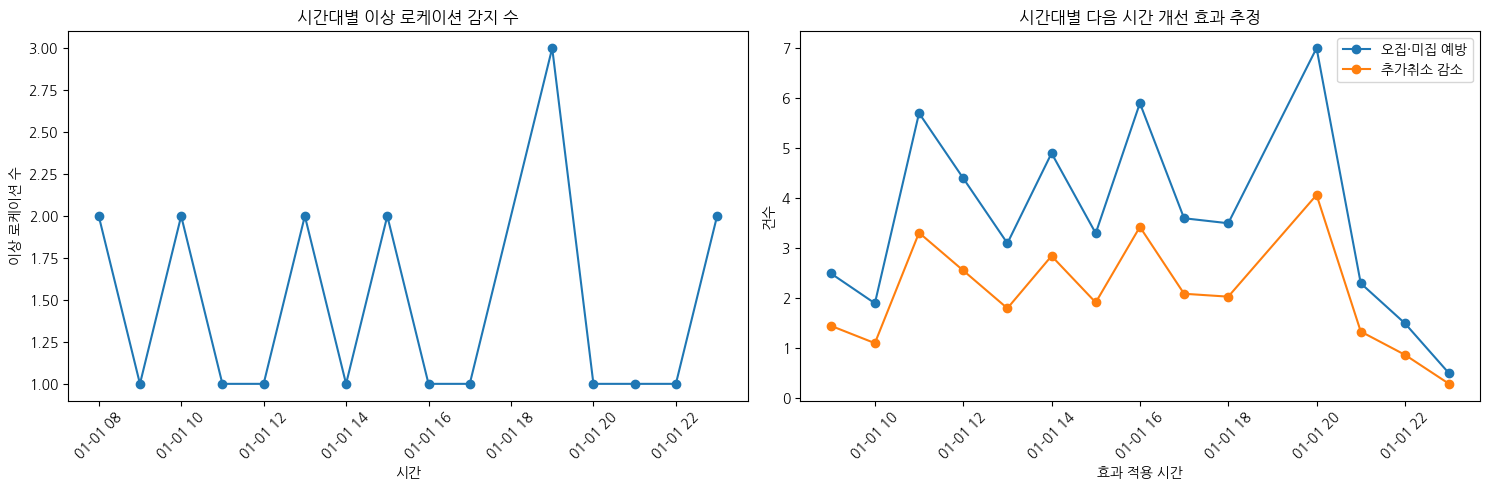

In [ ]:
# =============================================
# STEP 15-3: 시각화
# =============================================

import matplotlib.pyplot as plt

# 시간대별 이상 로케이션 수
outlier_by_hour = (
    outlier_locations
    .groupby('cancel_hour')
    .size()
    .reset_index(name='outlier_location_count')
)

# 시간대별 기대 예방 건수
effect_by_hour = (
    effect_hour_summary
    .groupby('cancel_hour')
    .agg(
        expected_prevented_error_count=('expected_prevented_error_count', 'sum'),
        expected_reduced_add_cancel_count=('expected_reduced_add_cancel_count', 'sum')
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    outlier_by_hour['cancel_hour'],
    outlier_by_hour['outlier_location_count'],
    marker='o'
)
axes[0].set_title('시간대별 이상 로케이션 감지 수')
axes[0].set_xlabel('시간')
axes[0].set_ylabel('이상 로케이션 수')
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(
    effect_by_hour['cancel_hour'],
    effect_by_hour['expected_prevented_error_count'],
    marker='o',
    label='오집·미집 예방'
)
axes[1].plot(
    effect_by_hour['cancel_hour'],
    effect_by_hour['expected_reduced_add_cancel_count'],
    marker='o',
    label='추가취소 감소'
)
axes[1].set_title('시간대별 다음 시간 개선 효과 추정')
axes[1].set_xlabel('효과 적용 시간')
axes[1].set_ylabel('건수')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 15-4: 자동화 후 추가 기능 효과 및 비용 절감 요약
# =============================================

AVG_COST_PER_ADD_CANCEL = 3000

daily_prevented_error_count = prevented_error_count
daily_reduced_add_cancel_count = reduced_add_cancel_count
daily_expected_saving = daily_reduced_add_cancel_count * AVG_COST_PER_ADD_CANCEL

print(
    f"자동화 개선 후 남아 있는 운영취소를 기준으로, "
    f"1시간 단위 이상 로케이션 교육 기능을 추가 적용하면 "
    f"하루 오집·미집 약 {daily_prevented_error_count:.1f}건을 예방하고, "
    f"추가취소 약 {daily_reduced_add_cancel_count:.1f}건을 추가로 줄일 수 있을 것으로 추정된다. "
    f"(예방으로 분모인 운영취소 건수가 함께 줄어 추가취소'율'은 거의 변하지 않으므로, "
    f"이 기능의 효과는 비율이 아닌 건수 감소로 읽는다.) "
    f"건당 평균 손실비용 {AVG_COST_PER_ADD_CANCEL:,}원 적용 시 "
    f"하루 약 {daily_expected_saving:,.0f}원의 추가 비용 절감 잠재효과가 있다."
)

자동화 개선 후 남아 있는 운영취소를 기준으로, 1시간 단위 이상 로케이션 교육 기능을 추가 적용하면 하루 오집·미집 약 50.1건을 예방하고, 추가취소 약 29.1건을 추가로 줄일 수 있을 것으로 추정된다. (예방으로 분모인 운영취소 건수가 함께 줄어 추가취소'율'은 거의 변하지 않으므로, 이 기능의 효과는 비율이 아닌 건수 감소로 읽는다.) 건당 평균 손실비용 3,000원 적용 시 하루 약 87,300원의 추가 비용 절감 잠재효과가 있다.


STEP 16. 기능 추가 시 월별 / 연간 추가 개선 효과 추정

[월별 추가 개선 효과]
 month  days  daily_orders  monthly_prevented_error_count  monthly_reduced_add_cancel_count  monthly_cost_saving
     1    31        148118                         1534.0                             891.0            2672345.0
     2    28        163727                         1531.0                             889.0            2668095.0
     3    31        167122                         1730.0                            1005.0            3015215.0
     4    30        171677                         1720.0                             999.0            2997480.0
     5    31        170589                         1766.0                            1026.0            3077767.0
     6    30        177026                         1774.0                            1030.0            3090874.0
     7    31        181603                         1880.0                            1092.0            3276481.0
     8    31        203868                  

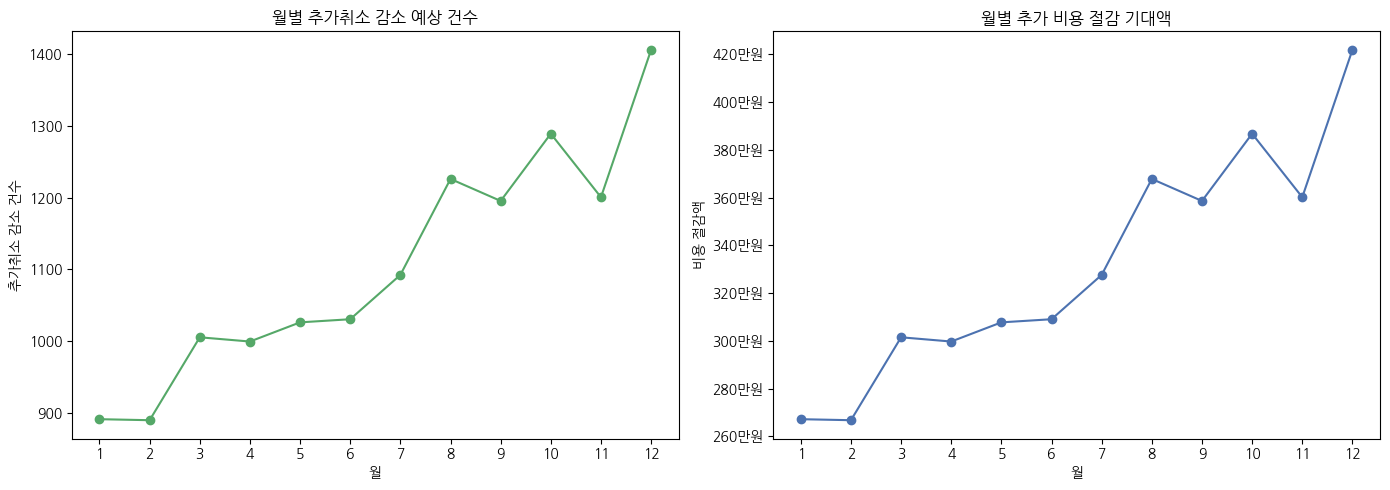

In [ ]:
# =============================================
# STEP 16: 기능 추가 시 월별 / 연간 추가 개선 효과 추정
# - 자동화 후 1시간 단위 이상 로케이션 교육 기능의 추가 효과
# =============================================

# STEP 15에서 계산된 하루 기준 효과 사용
base_daily_prevented_error = daily_prevented_error_count
base_daily_reduced_add_cancel = daily_reduced_add_cancel_count

# STEP 1의 N_ORDERS는 기준 일 주문량으로 해석
base_daily_orders = N_ORDERS

# 월별 일수
days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# STEP 12와 동일한 주문량 증가 가정
quarterly_daily_order_increase = 20000
monthly_daily_growth = quarterly_daily_order_increase / 3

# 주문량 변동성
ORDER_VOLUME_ERROR_RATE = 0.05

# 비용 가정
AVG_COST_PER_ADD_CANCEL = 3000
np.random.seed(42)
monthly_feature_results = []

for month in range(1, 13):
    # 월별 일 평균 주문량
    daily_orders = base_daily_orders + ((month - 1) * monthly_daily_growth)

    # 주문량 변동성 적용
    order_volume_multiplier = np.random.uniform(
        1 - ORDER_VOLUME_ERROR_RATE,
        1 + ORDER_VOLUME_ERROR_RATE
    )

    daily_orders_adj = int(daily_orders * order_volume_multiplier)

    # 기준 주문량 대비 스케일 조정
    order_scale = daily_orders_adj / base_daily_orders

    # 월별 기능 추가 효과
    monthly_prevented_error = (
        base_daily_prevented_error *
        order_scale *
        days_in_month[month - 1]
    )

    monthly_reduced_add_cancel = (
        base_daily_reduced_add_cancel *
        order_scale *
        days_in_month[month - 1]
    )

    monthly_cost_saving = monthly_reduced_add_cancel * AVG_COST_PER_ADD_CANCEL

    monthly_feature_results.append({
        'month': month,
        'days': days_in_month[month - 1],
        'daily_orders': daily_orders_adj,
        'order_scale': order_scale,
        'monthly_prevented_error_count': monthly_prevented_error,
        'monthly_reduced_add_cancel_count': monthly_reduced_add_cancel,
        'monthly_cost_saving': monthly_cost_saving
    })

monthly_feature_effect_df = pd.DataFrame(monthly_feature_results)

annual_feature_summary = pd.DataFrame({
    '지표': [
        '연간 오집·미집 예방 건수',
        '연간 추가취소 감소 건수',
        '건당 평균 손실비용',
        '연간 추가 비용 절감 기대액'
    ],
    '값': [
        monthly_feature_effect_df['monthly_prevented_error_count'].sum(),
        monthly_feature_effect_df['monthly_reduced_add_cancel_count'].sum(),
        AVG_COST_PER_ADD_CANCEL,
        monthly_feature_effect_df['monthly_cost_saving'].sum()
    ]
})

print("=" * 60)
print("STEP 16. 기능 추가 시 월별 / 연간 추가 개선 효과 추정")
print("=" * 60)

print("\n[월별 추가 개선 효과]")
print(
    monthly_feature_effect_df[
        [
            'month',
            'days',
            'daily_orders',
            'monthly_prevented_error_count',
            'monthly_reduced_add_cancel_count',
            'monthly_cost_saving'
        ]
    ].round(0).to_string(index=False)
)

print("\n[연간 추가 개선 효과 요약]")
print(annual_feature_summary.round(0).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    monthly_feature_effect_df['month'],
    monthly_feature_effect_df['monthly_reduced_add_cancel_count'],
    marker='o',
    color='#55A868'
)
axes[0].set_title('월별 추가취소 감소 예상 건수')
axes[0].set_xlabel('월')
axes[0].set_ylabel('추가취소 감소 건수')
axes[0].set_xticks(range(1, 13))

axes[1].plot(
    monthly_feature_effect_df['month'],
    monthly_feature_effect_df['monthly_cost_saving'],
    marker='o',
    color='#4C72B0'
)
axes[1].set_title('월별 추가 비용 절감 기대액')
axes[1].set_xlabel('월')
axes[1].set_ylabel('비용 절감액')
axes[1].set_xticks(range(1, 13))
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/10000:,.0f}만원')
)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================
# STEP 16-2: 연간 추가 개선 효과 한 줄 요약
# =============================================

annual_prevented_error = monthly_feature_effect_df['monthly_prevented_error_count'].sum()
annual_reduced_add_cancel = monthly_feature_effect_df['monthly_reduced_add_cancel_count'].sum()
annual_cost_saving = monthly_feature_effect_df['monthly_cost_saving'].sum()

print(
    f"자동화 이후 1시간 단위 이상 로케이션 교육 기능을 추가 적용하면, "
    f"연간 오집·미집 약 {annual_prevented_error:,.0f}건을 예방하고 "
    f"추가취소 약 {annual_reduced_add_cancel:,.0f}건을 추가로 줄일 수 있을 것으로 추정된다. "
    f"건당 평균 손실비용 {AVG_COST_PER_ADD_CANCEL:,}원 기준 "
    f"연간 약 {annual_cost_saving/10000:,.0f}만원의 추가 비용 절감 잠재효과가 있다."
)

자동화 이후 1시간 단위 이상 로케이션 교육 기능을 추가 적용하면, 연간 오집·미집 약 22,812건을 예방하고 추가취소 약 13,250건을 추가로 줄일 수 있을 것으로 추정된다. 건당 평균 손실비용 3,000원 기준 연간 약 3,975만원의 추가 비용 절감 잠재효과가 있다.


### 분석 해석

본 분석은 취소 기록을 단순 사후 처리 데이터가 아니라, 오집·미집 발생 원인을 추적하는 운영 개선 데이터로 활용한 확장 분석이다.

작업자 유형, 피크타임, 카테고리, 재고 구역을 조합하여 오집·미집이 집중되는 고위험 구간을 식별했고, 해당 구간을 재교육 대상으로 선정했다.

재교육 효과는 실제 사후 데이터가 아닌 시나리오 기반 기대효과이며, 고위험 구간의 오집·미집 발생이 10~30% 감소할 경우 추가취소가 얼마나 감소할 수 있는지 추정했다.

본 분석에서는 추가 기능 도입 시 연간 약 3,975만원의 비용 절감 잠재효과가 있음을 확인했다(셀 단위 시드 고정본 전체 재실행 기준).

실제 도입 여부는 개발 및 운영 비용과 비교해 ROI 기준으로 판단해야 하며, 본 프로젝트는 분석 관점에서 개선 가능성과 기대효과를 검증하는 데 초점을 두었다.